In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/home-credit-default-risk/application_test.csv
/kaggle/input/home-credit-default-risk/bureau_balance.csv
/kaggle/input/home-credit-default-risk/home-credit-default-risk.zip
/kaggle/input/home-credit-default-risk/POS_CASH_balance.csv
/kaggle/input/home-credit-default-risk/application_train.csv
/kaggle/input/home-credit-default-risk/sample_submission.csv
/kaggle/input/home-credit-default-risk/installments_payments.csv
/kaggle/input/home-credit-default-risk/previous_application.csv
/kaggle/input/home-credit-default-risk/credit_card_balance.csv
/kaggle/input/home-credit-default-risk/HomeCredit_columns_description.csv
/kaggle/input/home-credit-default-risk/bureau.csv


# Home Credit Default Risk – Muthoot Prep

## Step 1: Problem Statement
- **Problem type (of the 6):** Risk – credit default / application risk scoring
- **JD link:** Matches "Risk or fraud-related analytics" (ML use cases) and "credit analytics, lending products" (domain experience). JD-based.
- **Business problem:** Predict which loan applicants are likely to default, so we can approve good customers and reduce NPAs.
- **Who uses it:** Credit / underwriting team at the point of loan sanction (also useful for pricing and deciding loan amount).
- **Target:** `TARGET = 1` means the client had payment difficulties (late beyond a set number of days on at least one of the first instalments); `0` means all other cases.
- **Learning type:** Supervised learning, binary classification. The model outputs a probability of default, and the business chooses a cut-off to approve, review, or reject.

**Interview line**
- "I framed this as a supervised binary classification problem: predict the probability that an applicant defaults, so the credit team can approve, review or reject at sanction."

## Roadmap
**What we do**
- Follow 12 steps from the business problem to a monitored model.

**Flow:** Problem → Load → Join → EDA → Clean → Features → Split → Baseline → LightGBM → Tune → Evaluate → Errors → MLflow and monitoring

**Libraries flow:** Problem → Load (pandas) → Join (pandas merge) → EDA (pandas, matplotlib, scipy t-test and chi-square) → Clean (pandas, numpy) → Features (pandas, numpy, statsmodels VIF) → Split (scikit-learn train_test_split) → Baseline (scikit-learn LogisticRegression) → LightGBM (lightgbm) → Tune (scikit-learn RandomizedSearchCV) → Evaluate (scikit-learn metrics, matplotlib) → Errors and SHAP (shap) → MLflow and monitoring (mlflow, joblib)

**Steps**
- Step 1: Problem statement, load the data and check the target
- Step 2: Data collection, table relationships and the join (2.1 to 2.3)
- Step 3: EDA with missing values, t-tests, chi-square, anomalies and correlation
- Step 4: Data cleaning (anomaly flag, drop sparse columns, impute)
- Step 5: Feature engineering and WoE / IV
- Step 6: Train / validation split and encoding
- Step 7: Baseline logistic regression with AUC, Gini, KS, odds ratios and VIF
- Step 8: LightGBM with class imbalance handling and early stopping
- Step 9: Hyperparameter tuning
- Step 10: Evaluation, business cut-off, decile gains and SHAP
- Step 11: Error analysis by error type and segment
- Step 12: MLflow tracking, saving the model and PSI monitoring

**Why it matters**
- Shows the full ML lifecycle in order, which is what the JD asks for (JD-based).
- Easy to walk an interviewer through, one step at a time.

## Glossary
- **Default:** the borrower fails to repay as agreed. Here `TARGET = 1` means payment difficulties.
- **NPA (Non-Performing Asset):** in Indian lending, a loan with interest or principal overdue for more than 90 days.
- **DPD (Days Past Due):** how many days a payment is late. Buckets like 0-30, 31-60 and 61-90 track how bad it is getting.
- **CIBIL / credit bureau:** an agency that collects every customer's loans from all lenders and gives a credit report and score. The `bureau` table is like this.
- **One-to-many:** one applicant has many rows in another table, like many past loans in bureau.
- **LEFT JOIN:** keeps every row from the main table and adds matching info from the other table. No match gives NaN.
- **t-test:** checks whether the averages of two groups are really different or just different by chance.
- **Chi-square test:** checks whether a category (like income type) and an outcome (default) are linked.
- **p-value:** the chance of seeing a difference this big if there were really no difference. Below 0.05 we call it significant.
- **WoE (Weight of Evidence):** for each bin of a feature, ln(% of goods / % of bads). Positive means safer, negative means riskier.
- **IV (Information Value):** one number for how well a feature separates goods from bads. Above 0.1 is useful.
- **AUC:** the chance the model gives a random defaulter a higher score than a random good borrower. 0.5 is random and 1 is perfect.
- **Gini:** 2 x AUC - 1. The same information on a 0 to 1 scale, the usual metric in credit risk.
- **KS (Kolmogorov-Smirnov):** the biggest gap between the cumulative % of bads and goods across scores. Higher means better separation.
- **Odds ratio:** exp(coefficient). Above 1 raises the odds of default, below 1 lowers them.
- **VIF (Variance Inflation Factor):** how much a feature is explained by other features. Above 10 means strong overlap (multicollinearity).
- **PSI (Population Stability Index):** how much a distribution has shifted between two periods. Below 0.1 is stable.
- **SHAP:** explains each prediction by showing how much each feature pushed the risk up or down.
- **Threshold (cut-off):** the score above which we flag or reject an applicant.
- **Early stopping:** stop adding trees when validation performance stops improving, to avoid overfitting.
- **Class imbalance:** one class is much rarer than the other (about 8% defaults here), so the model must be told to pay more attention to it.

### Load data and check the target
**What we do**
- Load the main table (one row per loan application).
- Check rows and columns.
- Check how many applicants defaulted (1) vs did not (0).

**Why it matters**
- Confirms the data loaded correctly.
- Shows if defaults are rare. If they are, accuracy misleads, so we use AUC / Gini.

**Interview line**
- "First I checked the target and found defaults are only about 8% of applicants, so I knew accuracy would mislead and I used AUC, Gini and KS instead."

In [2]:
import pandas as pd, glob, os

# Find and load the main table
path = os.path.dirname(glob.glob('/kaggle/input/**/application_train.csv', recursive=True)[0])
app = pd.read_csv(f'{path}/application_train.csv')

# Size of the data
print(f"Loan applications: {app.shape[0]:,}")
print(f"Columns: {app.shape[1]}")

# Target split: 0 = repaid, 1 = payment difficulties
print(app['TARGET'].value_counts())
print(f"Default rate: {app['TARGET'].mean():.2%}")

Loan applications: 307,511
Columns: 122
TARGET
0    282686
1     24825
Name: count, dtype: int64
Default rate: 8.07%


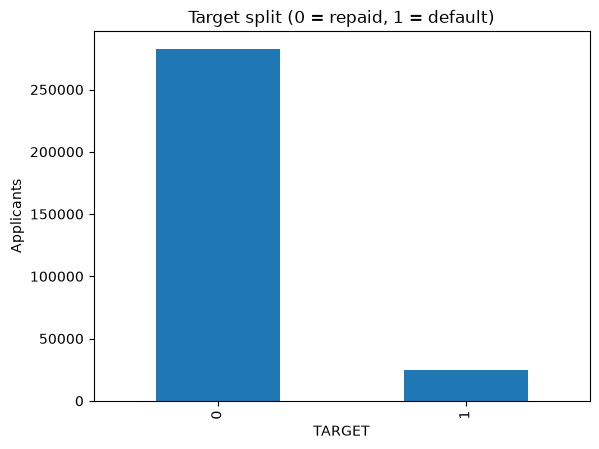

Imbalance ratio: 11.4 repaid applicants for every default


In [3]:
import matplotlib.pyplot as plt

# Bar chart of the target split
counts = app['TARGET'].value_counts()
counts.plot(kind='bar', title='Target split (0 = repaid, 1 = default)')
plt.ylabel('Applicants')
plt.show()

print(f"Imbalance ratio: {counts[0] / counts[1]:.1f} repaid applicants for every default")

**Findings**
- **How to read this:** if one bar is much taller than the other, the data is imbalanced. Then a model that always says "repaid" would look accurate but be useless, so we use AUC, Gini and KS.
- 307,511 applications: 282,686 repaid (0) and 24,825 defaulted (1), a default rate of 8.07%.
- Imbalance ratio is 11.4 repaid applicants for every default, so accuracy would mislead. We judge the model on AUC, Gini and KS.

## Step 2: Data Collection
**What we do**
- List all the tables we have.
- Check the size of each table.
- See which ID links each table to the main table.

**Why it matters**
- Shows what information we have about each applicant (bureau history, past loans, repayments).
- The main table alone has limited history. Joining the other tables adds strong signals like past late payments.

**Interview line**
- "I mapped all seven tables and their keys, because most of the predictive signal sits in the applicant's past credit and repayment history, not the application form."

In [4]:
# List every file in the data folder with its size
for f in sorted(os.listdir(path)):
    size_mb = os.path.getsize(f'{path}/{f}') / 1e6
    print(f"{f:40s} {size_mb:8.1f} MB")

# Load two linked tables to see their keys
bureau = pd.read_csv(f'{path}/bureau.csv')                  # loans from credit bureau
prev = pd.read_csv(f'{path}/previous_application.csv')      # earlier Home Credit applications

# Show the ID columns in each table
print("\nMain table IDs :", [c for c in app.columns if c.startswith('SK_ID')])
print("Bureau IDs     :", [c for c in bureau.columns if c.startswith('SK_ID')])
print("Previous IDs   :", [c for c in prev.columns if c.startswith('SK_ID')])

# How many past records each applicant has, on average
print(f"\nBureau records per applicant  : {bureau.groupby('SK_ID_CURR').size().mean():.1f}")
print(f"Previous apps per applicant    : {prev.groupby('SK_ID_CURR').size().mean():.1f}")

HomeCredit_columns_description.csv            0.0 MB
POS_CASH_balance.csv                        392.7 MB
application_test.csv                         26.6 MB
application_train.csv                       166.1 MB
bureau.csv                                  170.0 MB
bureau_balance.csv                          375.6 MB
credit_card_balance.csv                     424.6 MB
home-credit-default-risk.zip                721.6 MB
installments_payments.csv                   723.1 MB
previous_application.csv                    405.0 MB
sample_submission.csv                         0.5 MB



Main table IDs : ['SK_ID_CURR']
Bureau IDs     : ['SK_ID_CURR', 'SK_ID_BUREAU']
Previous IDs   : ['SK_ID_PREV', 'SK_ID_CURR']

Bureau records per applicant  : 5.6
Previous apps per applicant    : 4.9


**Findings**
- 10 files: 7 data tables, 1 test set, plus a column description file and a sample submission.
- `installments_payments` is the biggest table (723 MB).
- `SK_ID_CURR` links the main table, bureau and previous applications.
- Second-level keys: `SK_ID_BUREAU` (bureau → bureau_balance) and `SK_ID_PREV` (previous → POS, card, installments).
- Avg 5.6 bureau records and 4.9 previous applications per applicant, so both are one-to-many.

### Step 2.2: Check table relationships
**What we do**
- Compare rows vs unique IDs in each table.
- Count records per applicant and look at one applicant.

**Why it matters**
- Tells us if a table is one-to-one or one-to-many.
- One-to-many tables must be aggregated before joining, or applicants get duplicated.

**Domain link**
- In lending, one customer can hold several loans at other banks. The credit bureau (like CIBIL) keeps a record for each one.
- A risk team wants one summary line per customer, such as total loans, total debt and worst overdue.

**Interview line**
- "I checked rows against unique IDs to see which tables are one-to-many, because joining those directly would duplicate applicants."

In [5]:
# Is SK_ID_CURR unique in each table?
print("Main table   rows:", len(app),    "| unique IDs:", app['SK_ID_CURR'].nunique())
print("Bureau table rows:", len(bureau), "| unique IDs:", bureau['SK_ID_CURR'].nunique())

# Records per applicant in bureau
per_app = bureau.groupby('SK_ID_CURR').size()
print(f"Avg bureau records per applicant: {per_app.mean():.1f}, max: {per_app.max()}")

# One applicant's bureau records
one_id = bureau['SK_ID_CURR'].iloc[0]
bureau[bureau['SK_ID_CURR'] == one_id]

Main table   rows: 307511 | unique IDs: 307511
Bureau table rows: 1716428 | unique IDs: 305811
Avg bureau records per applicant: 5.6, max: 116


,SK_ID_CURR,SK_ID_BUREAU,CREDIT_ACTIVE,CREDIT_CURRENCY,DAYS_CREDIT,CREDIT_DAY_OVERDUE,DAYS_CREDIT_ENDDATE,DAYS_ENDDATE_FACT,AMT_CREDIT_MAX_OVERDUE,CNT_CREDIT_PROLONG,AMT_CREDIT_SUM,AMT_CREDIT_SUM_DEBT,AMT_CREDIT_SUM_LIMIT,AMT_CREDIT_SUM_OVERDUE,CREDIT_TYPE,DAYS_CREDIT_UPDATE,AMT_ANNUITY
0,215354,5714462,Closed,currency 1,-497,0,-153.0,-153.0,NaN,0,91323.0,0.00,NaN,0.0,Consumer credit,-131,NaN
1,215354,5714463,Active,currency 1,-208,0,1075.0,NaN,NaN,0,225000.0,171342.00,NaN,0.0,Credit card,-20,NaN
2,215354,5714464,Active,currency 1,-203,0,528.0,NaN,NaN,0,464323.5,NaN,NaN,0.0,Consumer credit,-16,NaN
3,215354,5714465,Active,currency 1,-203,0,NaN,NaN,NaN,0,90000.0,NaN,NaN,0.0,Credit card,-16,NaN
4,215354,5714466,Active,currency 1,-629,0,1197.0,NaN,77674.5,0,2700000.0,NaN,NaN,0.0,Consumer credit,-21,NaN
5,215354,5714467,Active,currency 1,-273,0,27460.0,NaN,0.0,0,180000.0,71017.38,108982.62,0.0,Credit card,-31,NaN
6,215354,5714468,Active,currency 1,-43,0,79.0,NaN,0.0,0,42103.8,42103.80,0.00,0.0,Consumer credit,-22,NaN
225157,215354,5714458,Closed,currency 1,-1872,0,-776.0,-1203.0,NaN,0,494550.0,0.00,0.00,0.0,Consumer credit,-696,NaN
225158,215354,5714459,Closed,currency 1,-1734,0,-638.0,-1336.0,NaN,0,1084032.0,0.00,NaN,0.0,Car loan,-1336,NaN
225159,215354,5714460,Closed,currency 1,-1333,0,-1089.0,-987.0,NaN,0,102150.0,NaN,NaN,0.0,Consumer credit,-984,NaN


**Findings**
- Main table: 307,511 rows and 307,511 unique `SK_ID_CURR`, so it's one row per applicant (one-to-one).
- Bureau table: 1,716,428 rows but only 305,811 unique `SK_ID_CURR`, so it's one-to-many.
- Applicants average 5.6 bureau records, and the most for one applicant is 116.
- Sample applicant 215354 has 11 bureau loans: 6 active and 5 closed.
- Not every applicant has bureau history, so after the join some rows will be blank (NaN) for bureau features. That's useful in itself, because "no credit history" tells us something.
- Next step: summarise bureau to one row per applicant, then LEFT JOIN it to the main table.

### Step 2.3: Summarise the history tables and join them (GROUP BY, then LEFT JOIN)
**What we do**
- Summarise `bureau` to one row per applicant: loan count, active loan count, worst current overdue days, total outstanding debt, total credit amount and how long ago (on average) the loans were opened.
- Summarise `prev` (earlier Home Credit applications) to one row per applicant: count, approved count, refused count and average amount asked for.
- Summarise `installments_payments` to one row per applicant: share of instalments paid late and average "paid vs due" ratio. We load only the 5 columns we need to save memory.
- LEFT JOIN all three summaries onto the main table to make `df`, then check the row count did not change.

**Why it matters**
- The model needs exactly one row per applicant. Aggregating first stops applicants from being duplicated.
- A LEFT JOIN keeps every applicant, even those with no history. Those rows get NaN, which we handle in Step 4.
- Past behaviour (refusals, late payments, existing debt) is usually the strongest signal for future default.

**Domain link**
- This is how a lender reads a CIBIL report: number of live loans, total outstanding, any DPD (days past due) and past rejections.
- Late instalments here are like DPD buckets in Indian lending. Repeated late payment is an early warning before a loan turns NPA (90+ DPD).
- JD-based: "risk analytics" and "data preparation" in the ML lifecycle. Domain-based: CIBIL and DPD thinking.

**Interview line**
- "I summarised each history table to one row per applicant with GROUP BY and then LEFT JOINed it, so every applicant stays in, including those with no credit history."

In [6]:
import numpy as np

print(f"Shape before join: {app.shape}")

# 1. Bureau: one row per applicant
bureau['IS_ACTIVE'] = (bureau['CREDIT_ACTIVE'] == 'Active').astype(int)
bureau_agg = bureau.groupby('SK_ID_CURR').agg(
    BUREAU_LOAN_COUNT=('SK_ID_BUREAU', 'count'),
    BUREAU_ACTIVE_COUNT=('IS_ACTIVE', 'sum'),
    BUREAU_MAX_OVERDUE_DAYS=('CREDIT_DAY_OVERDUE', 'max'),
    BUREAU_TOTAL_DEBT=('AMT_CREDIT_SUM_DEBT', 'sum'),
    BUREAU_TOTAL_CREDIT=('AMT_CREDIT_SUM', 'sum'),
    BUREAU_MEAN_DAYS_CREDIT=('DAYS_CREDIT', 'mean'),
).reset_index()
print(f"Bureau summary shape      : {bureau_agg.shape}")

# 2. Previous applications: one row per applicant
prev['IS_APPROVED'] = (prev['NAME_CONTRACT_STATUS'] == 'Approved').astype(int)
prev['IS_REFUSED'] = (prev['NAME_CONTRACT_STATUS'] == 'Refused').astype(int)
prev_agg = prev.groupby('SK_ID_CURR').agg(
    PREV_APP_COUNT=('SK_ID_PREV', 'count'),
    PREV_APPROVED_COUNT=('IS_APPROVED', 'sum'),
    PREV_REFUSED_COUNT=('IS_REFUSED', 'sum'),
    PREV_MEAN_AMT_APPLICATION=('AMT_APPLICATION', 'mean'),
).reset_index()
print(f"Previous apps summary shape: {prev_agg.shape}")

# 3. Installments: load only the 5 columns we need (saves memory)
cols = ['SK_ID_CURR', 'DAYS_INSTALMENT', 'DAYS_ENTRY_PAYMENT', 'AMT_INSTALMENT', 'AMT_PAYMENT']
inst = pd.read_csv(f'{path}/installments_payments.csv', usecols=cols)
inst['IS_LATE'] = (inst['DAYS_ENTRY_PAYMENT'] > inst['DAYS_INSTALMENT']).astype(int)
# paid / due (1.0 = paid in full); skip rows where nothing was due
inst['PAYMENT_RATIO'] = np.where(inst['AMT_INSTALMENT'] > 0, inst['AMT_PAYMENT'] / inst['AMT_INSTALMENT'], np.nan)
inst_agg = inst.groupby('SK_ID_CURR').agg(
    INST_LATE_RATE=('IS_LATE', 'mean'),
    INST_MEAN_PAYMENT_RATIO=('PAYMENT_RATIO', 'mean'),
).reset_index()
print(f"Installments summary shape : {inst_agg.shape}")

# 4. LEFT JOIN each summary onto the main table
df = app.merge(bureau_agg, on='SK_ID_CURR', how='left')
df = df.merge(prev_agg, on='SK_ID_CURR', how='left')
df = df.merge(inst_agg, on='SK_ID_CURR', how='left')
print(f"\nShape after join : {df.shape}")
assert len(df) == len(app)
print("Row count unchanged after join: OK")

# Applicants with no bureau history
no_bureau = df['BUREAU_LOAN_COUNT'].isna()
print(f"Applicants with no bureau history: {no_bureau.sum():,} ({no_bureau.mean():.2%})")
print(f"Default rate - no bureau history : {df.loc[no_bureau, 'TARGET'].mean():.2%}")
print(f"Default rate - has bureau history: {df.loc[~no_bureau, 'TARGET'].mean():.2%}")

Shape before join: (307511, 122)


Bureau summary shape      : (305811, 7)
Previous apps summary shape: (338857, 5)


Installments summary shape : (339587, 3)

Shape after join : (307511, 134)
Row count unchanged after join: OK
Applicants with no bureau history: 44,020 (14.31%)
Default rate - no bureau history : 10.12%
Default rate - has bureau history: 7.73%


**Findings**
- **How to read this:** The row count must stay the same after a LEFT JOIN. If it goes up, a table was not aggregated first.
- Shape went from (307511, 122) to (307511, 134): 12 new history features and the same 307,511 rows. The assert passed ("Row count unchanged after join: OK").
- Summary tables: bureau (305811, 7), previous applications (338857, 5), installments (339587, 3).
- 44,020 applicants (14.31%) have no bureau history.
- No bureau history means higher risk: 10.12% default rate vs 7.73% for applicants with history. "Thin file" customers need extra care, and `NO_BUREAU_HISTORY` is worth keeping as a feature.

## Step 3: Exploratory Data Analysis (EDA)
**What we do**
- 3.1 Check missing values.
- 3.2 Compare numeric features between defaulters and non-defaulters (t-test).
- 3.3 Compare default rate across categories (chi-square).
- 3.4 Find anomalies (the `DAYS_EMPLOYED = 365243` value).
- 3.5 Find the features most correlated with `TARGET`.

**Why it matters**
- EDA tells us what to clean, which features carry signal and which business story the data tells.
- Statistical tests show whether a difference is real or just noise.

**Stats used:** t-test, chi-square test, correlation.

JD-based: "exploratory analysis" and "statistical analysis" in the JD.

**Interview line**
- "Before modelling I used EDA and simple statistical tests to find which features really separate defaulters from good borrowers."

### Step 3.1: Missing values
**What we do**
- Calculate the % missing for every column and show the top 20.
- Count the columns that are more than 60% missing.

**Why it matters**
- Columns that are mostly empty add noise and memory. Our rule: drop a column if more than 60% is missing.
- Columns with some missing values are kept and filled (imputed) in Step 4.
- Sometimes "missing" is a signal in itself, like no bureau history.

**Interview line**
- "I profiled missing values and set a clear rule: drop columns over 60% missing and impute the rest."

In [7]:
# % missing per column, highest first
missing_pct = (df.isna().mean() * 100).sort_values(ascending=False)
print(missing_pct.head(20).round(1))

print(f"\nColumns with any missing value : {(missing_pct > 0).sum()}")
print(f"Columns with > 60% missing     : {(missing_pct > 60).sum()}")
print(f"Total columns                  : {df.shape[1]}")

COMMONAREA_AVG              69.9
COMMONAREA_MODE             69.9
COMMONAREA_MEDI             69.9
NONLIVINGAPARTMENTS_AVG     69.4
NONLIVINGAPARTMENTS_MEDI    69.4
NONLIVINGAPARTMENTS_MODE    69.4
FONDKAPREMONT_MODE          68.4
LIVINGAPARTMENTS_MEDI       68.4
LIVINGAPARTMENTS_AVG        68.4
LIVINGAPARTMENTS_MODE       68.4
FLOORSMIN_MODE              67.8
FLOORSMIN_AVG               67.8
FLOORSMIN_MEDI              67.8
YEARS_BUILD_MEDI            66.5
YEARS_BUILD_MODE            66.5
YEARS_BUILD_AVG             66.5
OWN_CAR_AGE                 66.0
LANDAREA_MEDI               59.4
LANDAREA_MODE               59.4
LANDAREA_AVG                59.4
dtype: float64

Columns with any missing value : 79
Columns with > 60% missing     : 17
Total columns                  : 134


**Findings**
- **How to read this:** Below 60% missing we keep and fill the column. Above 60% we drop it. A missing value can itself be a signal.
- The most-missing columns are COMMONAREA_AVG, COMMONAREA_MODE and COMMONAREA_MEDI at 69.9%.
- The top 20 is dominated by building and apartment details (COMMONAREA, NONLIVINGAPARTMENTS, LIVINGAPARTMENTS, FLOORSMIN, YEARS_BUILD, LANDAREA) plus OWN_CAR_AGE at 66.0%. Many applicants simply do not report property details.
- 79 of 134 columns have at least one missing value, and 17 are more than 60% missing, so they are dropped in Step 4.
- None of the new bureau, previous or installment columns are in the top 20, so the join added little missingness.

### Step 3.2: Target vs numeric features (t-test)
**What we do**
- Compare the average of `EXT_SOURCE_1`, `EXT_SOURCE_2`, `EXT_SOURCE_3`, `AMT_CREDIT` and age between defaulters (1) and non-defaulters (0).
- Run a t-test for each to check whether the difference is statistically significant.
- Plot the density of each `EXT_SOURCE` score for both groups.

**Why it matters**
- Shows which numeric features separate good and bad borrowers.
- p-value < 0.05 means the difference is unlikely to be random.
- With 300k rows almost everything is "significant", so we also look at how big the gap in means is.

**Stats used:** Welch's t-test (two-sample t-test that does not assume equal variance).

**Domain link**
- `EXT_SOURCE` scores are external credit scores, similar to a CIBIL score. Higher should mean safer.

**Interview line**
- "I used Welch's t-test to confirm defaulters have significantly lower external credit scores and are younger on average."

EXT_SOURCE_1  | mean non-default:        0.511 | mean default:        0.387 | t =   58.55 | p = 0.00e+00
EXT_SOURCE_2  | mean non-default:        0.523 | mean default:        0.411 | t =   80.47 | p = 0.00e+00
EXT_SOURCE_3  | mean non-default:        0.521 | mean default:        0.391 | t =   84.58 | p = 0.00e+00
AMT_CREDIT    | mean non-default:  602,648.282 | mean default:  557,778.528 | t =   19.27 | p = 2.72e-82
AGE_YEARS     | mean non-default:       44.184 | mean default:       40.752 | t =   45.01 | p = 0.00e+00


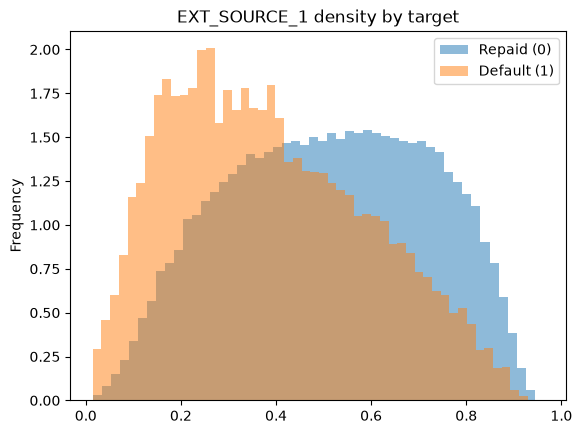

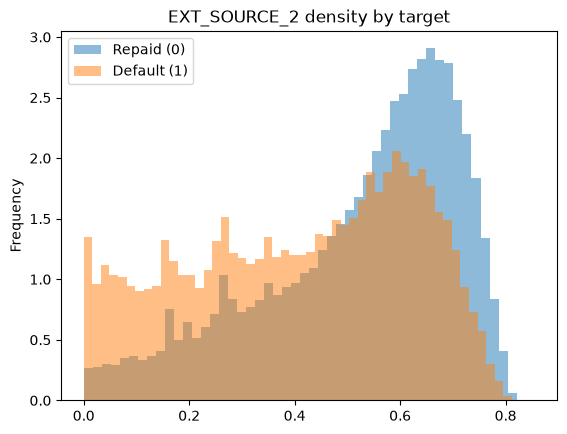

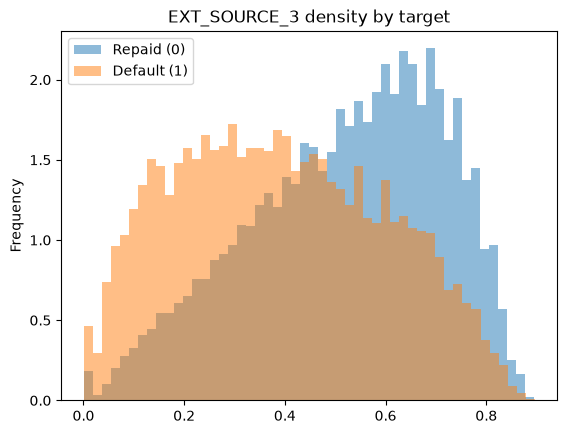

In [8]:
from scipy import stats
import matplotlib.pyplot as plt

df_age = -df['DAYS_BIRTH'] / 365.25    # age in years
features = {'EXT_SOURCE_1': df['EXT_SOURCE_1'], 'EXT_SOURCE_2': df['EXT_SOURCE_2'],
            'EXT_SOURCE_3': df['EXT_SOURCE_3'], 'AMT_CREDIT': df['AMT_CREDIT'], 'AGE_YEARS': df_age}

for name, col in features.items():
    good = col[df['TARGET'] == 0].dropna()
    bad = col[df['TARGET'] == 1].dropna()
    t, p = stats.ttest_ind(good, bad, equal_var=False)    # Welch's t-test
    print(f"{name:13s} | mean non-default: {good.mean():12,.3f} | mean default: {bad.mean():12,.3f} "
          f"| t = {t:7.2f} | p = {p:.2e}")

# Density of each EXT_SOURCE for repaid vs default
for col in ['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3']:
    df.loc[df['TARGET'] == 0, col].plot(kind='hist', bins=50, alpha=0.5, density=True, label='Repaid (0)')
    df.loc[df['TARGET'] == 1, col].plot(kind='hist', bins=50, alpha=0.5, density=True, label='Default (1)')
    plt.title(f'{col} density by target')
    plt.legend()
    plt.show()

**Findings**
- **How to read this:** p < 0.05 means the gap between the two group means is unlikely to be chance. Also look at how big the gap is. In the density plots, less overlap between the two curves means a stronger feature.
- All three external scores are lower for defaulters: EXT_SOURCE_1 0.387 vs 0.511, EXT_SOURCE_2 0.411 vs 0.523, EXT_SOURCE_3 0.391 vs 0.521 (default vs non-default).
- Defaulters are younger on average: 40.752 years vs 44.184 years.
- Defaulters took slightly smaller loans on average (557,778.528 vs 602,648.282), so loan size alone is a weak signal.
- All five p-values are below 0.05. The biggest |t| is EXT_SOURCE_3 (t = 84.58), then EXT_SOURCE_2 (80.47) and EXT_SOURCE_1 (58.55). The EXT_SOURCE p-values print as 0.00e+00 because they are smaller than the computer can display.
- The t-statistics point to EXT_SOURCE_3 as the most separated score. The density plots show the default curve shifted towards lower scores for all three.

### Step 3.3: Categorical features vs target (default rate and chi-square)
**What we do**
- Show the default rate for each category of `NAME_CONTRACT_TYPE`, `CODE_GENDER`, `NAME_EDUCATION_TYPE` and `NAME_INCOME_TYPE`.
- Run a chi-square test of independence for each.
- Plot the default rate by category against the overall default rate.

**Why it matters**
- Shows which customer groups are riskier.
- Chi-square p-value < 0.05 means default and the category are linked (not independent).

**Stats used:** chi-square test of independence.

**Domain link**
- Lenders segment risk by product (cash vs revolving loans) and by income type (salaried vs self-employed). These groups often get different pricing and cut-offs.
- Fairness note: gender may be significant but should not be used to decide credit. Mention this if asked about responsible AI.

**Interview line**
- "I compared default rates across segments and used chi-square tests to confirm that contract type, education and income type are linked to default."


=== NAME_CONTRACT_TYPE ===
                    applicants  default_rate
NAME_CONTRACT_TYPE                          
Cash loans              278232          8.35
Revolving loans          29279          5.48
Chi-square = 293.2 | dof = 1 | p = 1.02e-65


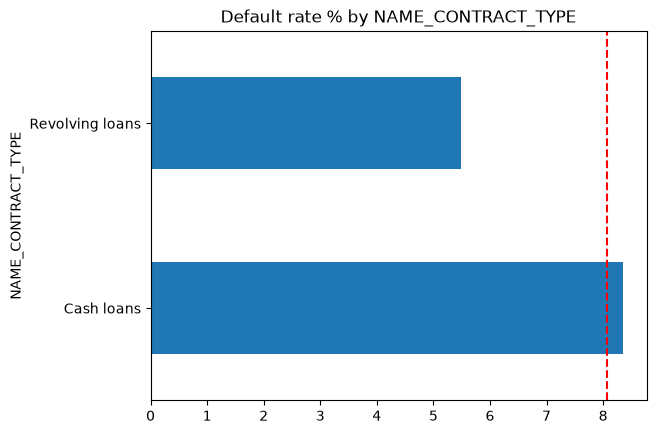


=== CODE_GENDER ===
             applicants  default_rate
CODE_GENDER                          
M                105059         10.14
F                202448          7.00
XNA                   4          0.00
Chi-square = 920.8 | dof = 2 | p = 1.13e-200


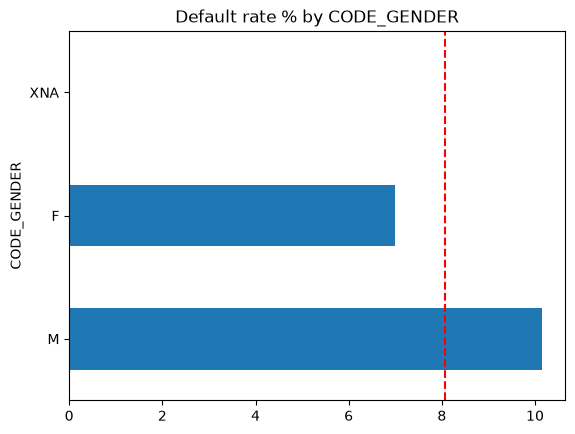


=== NAME_EDUCATION_TYPE ===
                               applicants  default_rate
NAME_EDUCATION_TYPE                                    
Lower secondary                      3816         10.93
Secondary / secondary special      218391          8.94
Incomplete higher                   10277          8.48
Higher education                    74863          5.36
Academic degree                       164          1.83


Chi-square = 1,019.2 | dof = 4 | p = 2.45e-219


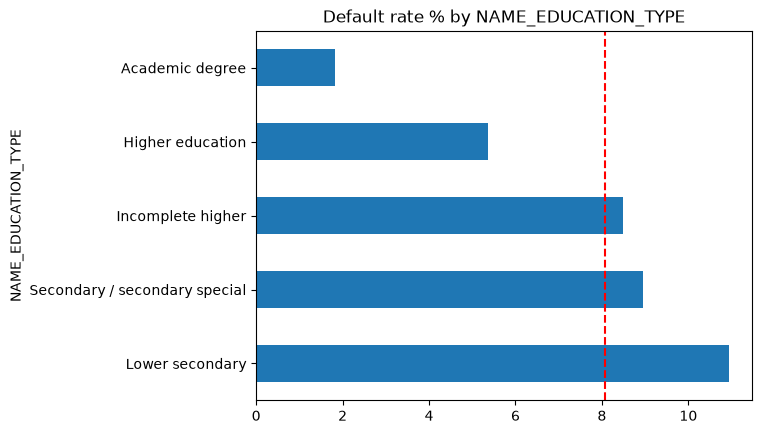


=== NAME_INCOME_TYPE ===
                      applicants  default_rate
NAME_INCOME_TYPE                              
Maternity leave                5         40.00
Unemployed                    22         36.36
Working                   158774          9.59
Commercial associate       71617          7.48
State servant              21703          5.75
Pensioner                  55362          5.39
Businessman                   10          0.00
Student                       18          0.00


Chi-square = 1,253.5 | dof = 7 | p = 1.93e-266


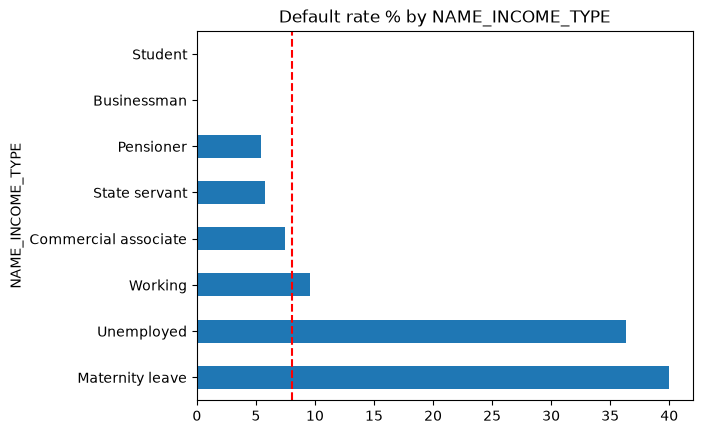

In [9]:
cat_check = ['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'NAME_EDUCATION_TYPE', 'NAME_INCOME_TYPE']
overall_rate = df['TARGET'].mean() * 100

for col in cat_check:
    # Applicants and default rate (%) per category
    summary = df.groupby(col)['TARGET'].agg(applicants='count', default_rate='mean')
    summary['default_rate'] = (summary['default_rate'] * 100).round(2)
    summary = summary.sort_values('default_rate', ascending=False)
    print(f"\n=== {col} ===")
    print(summary)

    # Chi-square test on the category vs target counts
    chi2, p, dof, _ = stats.chi2_contingency(pd.crosstab(df[col], df['TARGET']))
    print(f"Chi-square = {chi2:,.1f} | dof = {dof} | p = {p:.2e}")

    # Bar chart; red line = overall default rate
    summary['default_rate'].plot(kind='barh', title=f'Default rate % by {col}')
    plt.axvline(overall_rate, color='red', linestyle='--')
    plt.show()

**Findings**
- **How to read this:** p < 0.05 means the category and default are linked. In the bar charts, bars far from the red overall line are the riskier or safer groups. Ignore rates from tiny categories.
- Cash loans default at 8.35% vs 5.48% for revolving loans (chi-square 293.2, p = 1.02e-65).
- Education: lower secondary is the riskiest at 10.93% and higher education is much safer at 5.36%. Income type: Working is the riskiest large group at 9.59%, while pensioners are at 5.39%.
- Tiny categories are unreliable: Maternity leave (5 applicants, 40.00%), Unemployed (22, 36.36%), Businessman (10, 0.00%), Student (18, 0.00%), and CODE_GENDER XNA (4 applicants).
- All four chi-square tests have p < 0.05: contract type 1.02e-65, gender 1.13e-200, education 2.45e-219, income type 1.93e-266. Men default at 10.14% vs 7.00% for women, but gender should not drive credit decisions.

### Step 3.4: Anomalies (DAYS_EMPLOYED = 365243)
**What we do**
- Count rows where `DAYS_EMPLOYED` is 365243, which is about +1,000 years and impossible.
- Check which income type these rows belong to and their default rate.

**Why it matters**
- Placeholder values like this distort averages and the model.
- They usually mean something, here most likely "not employed / pensioner", so we keep that information as a flag before fixing the value.

**Domain link**
- Pensioners and unemployed applicants are a separate segment in lending. A gold loan, for example, depends on collateral rather than employment.

**Interview line**
- "I found a placeholder value of 365243 days in employment, mostly pensioners, so I replaced it with a flag instead of letting it distort the model."

In [10]:
anom = df['DAYS_EMPLOYED'] == 365243
print(f"Rows with DAYS_EMPLOYED = 365243 : {anom.sum():,} ({anom.mean():.2%})")
print(f"Default rate - anomaly rows      : {df.loc[anom, 'TARGET'].mean():.2%}")
print(f"Default rate - other rows        : {df.loc[~anom, 'TARGET'].mean():.2%}")

print("\nIncome type of anomaly rows:")
print(df.loc[anom, 'NAME_INCOME_TYPE'].value_counts())

years = -df.loc[~anom, 'DAYS_EMPLOYED'] / 365.25
print(f"\nYears employed (excluding anomaly): min {years.min():.1f}, max {years.max():.1f}")

Rows with DAYS_EMPLOYED = 365243 : 55,374 (18.01%)
Default rate - anomaly rows      : 5.40%
Default rate - other rows        : 8.66%

Income type of anomaly rows:
NAME_INCOME_TYPE
Pensioner     55352
Unemployed       22
Name: count, dtype: int64



Years employed (excluding anomaly): min 0.0, max 49.0


**Findings**
- **How to read this:** If the anomaly rows have a very different default rate, the flag is useful information, not just noise.
- 55,374 rows (18.01%) have DAYS_EMPLOYED = 365243.
- These are almost all pensioners (55,352) plus 22 unemployed, so the value means "not employed" rather than a data error.
- These rows default less: 5.40% vs 8.66% for everyone else. The `DAYS_EMPLOYED_ANOM` flag keeps this useful signal.
- Without the anomaly, years employed ranges from 0.0 to 49.0, which is realistic.

### Step 3.5: Correlation with TARGET
**What we do**
- Calculate the correlation of every numeric column with `TARGET`.
- Show the top 10 positive (higher value = more default) and top 10 negative (higher value = less default).

**Why it matters**
- A quick ranking of the strongest single signals.
- Correlation only captures straight-line relationships and does not prove cause. The model in Step 8 can find more complex patterns.

**Stats used:** Pearson correlation (with a 0/1 target this is the point-biserial correlation).

**Interview line**
- "A quick correlation ranking showed the external scores and repayment history are the strongest single signals."

In [11]:
num_cols = df.select_dtypes('number').columns.drop(['TARGET', 'SK_ID_CURR'])
corr = df[num_cols].corrwith(df['TARGET']).dropna()    # dropna: constant columns give NaN

print("Top 10 positive correlations (higher value -> more default):")
print(corr.sort_values(ascending=False).head(10).round(4))
print("\nTop 10 negative correlations (higher value -> less default):")
print(corr.sort_values().head(10).round(4))

Top 10 positive correlations (higher value -> more default):
BUREAU_MEAN_DAYS_CREDIT        0.0897
DAYS_BIRTH                     0.0782
INST_LATE_RATE                 0.0700
BUREAU_ACTIVE_COUNT            0.0671
PREV_REFUSED_COUNT             0.0645
REGION_RATING_CLIENT_W_CITY    0.0609
REGION_RATING_CLIENT           0.0589
DAYS_LAST_PHONE_CHANGE         0.0552
DAYS_ID_PUBLISH                0.0515
REG_CITY_NOT_WORK_CITY         0.0510
dtype: float64

Top 10 negative correlations (higher value -> less default):
EXT_SOURCE_3                 -0.1789
EXT_SOURCE_2                 -0.1605
EXT_SOURCE_1                 -0.1553
DAYS_EMPLOYED                -0.0449
FLOORSMAX_AVG                -0.0440
FLOORSMAX_MEDI               -0.0438
FLOORSMAX_MODE               -0.0432
AMT_GOODS_PRICE              -0.0396
REGION_POPULATION_RELATIVE   -0.0372
ELEVATORS_AVG                -0.0342
dtype: float64


**Findings**
- **How to read this:** Correlation runs from -1 to +1. For default prediction, even 0.1 to 0.2 is meaningful because default depends on many small factors.
- Top positive correlations: BUREAU_MEAN_DAYS_CREDIT 0.0897, DAYS_BIRTH 0.0782 and INST_LATE_RATE 0.0700.
- Top negative correlations are the external scores: EXT_SOURCE_3 -0.1789, EXT_SOURCE_2 -0.1605 and EXT_SOURCE_1 -0.1553.
- Our joined features made the top 10: BUREAU_MEAN_DAYS_CREDIT, INST_LATE_RATE (late payment history), BUREAU_ACTIVE_COUNT 0.0671 and PREV_REFUSED_COUNT 0.0645. The join added real signal.
- The largest absolute correlation is only 0.1789 (EXT_SOURCE_3). No single feature is enough, so we need a model that combines many.

## Step 4: Data Cleaning
**What we do**
- Turn `DAYS_EMPLOYED = 365243` into NaN and add a flag column `DAYS_EMPLOYED_ANOM`.
- Fill missing count columns from the joined tables with 0 (no record = zero loans) and add a `NO_BUREAU_HISTORY` flag.
- Drop columns with more than 60% missing.
- Fill other missing numeric values with the median, and missing categorical values with "Missing".

**Why it matters**
- Logistic regression cannot handle NaN, so every value needs filling.
- Median is safer than mean because amounts like income are skewed.
- "Missing" as its own category keeps the information that the value was not given.
- Simple version: medians are calculated on all data. In production we calculate them on training data only and save them for the app (we save them in Step 12).

JD-based: "data cleaning and preparation" in the ML lifecycle.

**Interview line**
- "I cleaned the data with simple, explainable rules: flag anomalies, zero-fill missing history counts, drop very sparse columns and median-impute the rest."

In [12]:
df_clean = df.copy()

# 1. Anomaly -> flag column, then NaN
df_clean['DAYS_EMPLOYED_ANOM'] = (df_clean['DAYS_EMPLOYED'] == 365243).astype(int)
df_clean['DAYS_EMPLOYED'] = df_clean['DAYS_EMPLOYED'].replace(365243, np.nan)

# 2. No history record = 0 loans (plus a flag)
df_clean['NO_BUREAU_HISTORY'] = df_clean['BUREAU_LOAN_COUNT'].isna().astype(int)
zero_fill = ['BUREAU_LOAN_COUNT', 'BUREAU_ACTIVE_COUNT', 'BUREAU_TOTAL_DEBT', 'BUREAU_TOTAL_CREDIT',
             'PREV_APP_COUNT', 'PREV_APPROVED_COUNT', 'PREV_REFUSED_COUNT']
df_clean[zero_fill] = df_clean[zero_fill].fillna(0)

# 3. Drop columns with > 60% missing
missing_pct = df_clean.isna().mean() * 100
drop_cols = missing_pct[missing_pct > 60].index
df_clean = df_clean.drop(columns=drop_cols)
print(f"Dropped {len(drop_cols)} columns with > 60% missing")

# 4. Median for numeric, "Missing" for text columns
num_cols = df_clean.select_dtypes('number').columns.drop('TARGET')
cat_cols = df_clean.select_dtypes(include=['object', 'string']).columns
num_medians = df_clean[num_cols].median()          # saved later for the app
df_clean[num_cols] = df_clean[num_cols].fillna(num_medians)
df_clean[cat_cols] = df_clean[cat_cols].fillna('Missing')

print(f"Shape after cleaning      : {df_clean.shape}")
print(f"Numeric columns           : {len(num_cols)}")
print(f"Categorical columns       : {len(cat_cols)}")
print(f"Missing values remaining  : {df_clean.isna().sum().sum()}")

Dropped 17 columns with > 60% missing


Shape after cleaning      : (307511, 119)
Numeric columns           : 103
Categorical columns       : 15
Missing values remaining  : 0


**Findings**
- 17 columns with more than 60% missing were dropped.
- Final shape is (307511, 119) with 103 numeric and 15 categorical columns.
- Missing values remaining: 0, so the data is ready for logistic regression.

## Step 5: Feature Engineering and WoE / IV
**What we do**
- Create business features:
  - `AGE_YEARS` and `YEARS_EMPLOYED` (from days to years).
  - `CREDIT_INCOME_RATIO` = loan amount / income.
  - `ANNUITY_INCOME_RATIO` = yearly EMI / income (like FOIR in Indian lending).
  - `CREDIT_TERM` = loan amount / annuity (rough number of instalments).
  - `EXT_SOURCE_MEAN` = average of the external scores.
  - `DEBT_TO_CREDIT` = bureau outstanding debt / bureau total credit.
- Calculate Weight of Evidence (WoE) and Information Value (IV) for a few binned features.

**Why it matters**
- Ratios capture affordability better than raw amounts. A ₹10 lakh loan is risky on a ₹3 lakh income but fine on ₹30 lakh.
- WoE/IV is the classic credit-scorecard way to rank features and is what risk teams expect you to know.
- IV rule of thumb:
  - < 0.02: not useful
  - 0.02 to 0.1: weak
  - 0.1 to 0.3: medium
  - 0.3 to 0.5: strong
  - > 0.5: suspicious, check for leakage

**Stats used:** Weight of Evidence (WoE), Information Value (IV).

**Domain link**
- FOIR (Fixed Obligation to Income Ratio) is a standard eligibility check in Indian lending. `ANNUITY_INCOME_RATIO` is a simple version of it.
- Domain-based: credit scorecard practice. JD-based: "feature engineering".

**Interview line**
- "I built affordability ratios like credit-to-income and EMI-to-income, similar to FOIR, and ranked features with WoE and IV the way a credit scorecard team would."

In [13]:
df_fe = df_clean.copy()

df_fe['AGE_YEARS'] = -df_fe['DAYS_BIRTH'] / 365.25
df_fe['YEARS_EMPLOYED'] = -df_fe['DAYS_EMPLOYED'] / 365.25
df_fe['CREDIT_INCOME_RATIO'] = df_fe['AMT_CREDIT'] / df_fe['AMT_INCOME_TOTAL']
df_fe['ANNUITY_INCOME_RATIO'] = df_fe['AMT_ANNUITY'] / df_fe['AMT_INCOME_TOTAL']
df_fe['CREDIT_TERM'] = df_fe['AMT_CREDIT'] / df_fe['AMT_ANNUITY']
df_fe['EXT_SOURCE_MEAN'] = df_fe[['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3']].mean(axis=1)
# debt / credit, or 0 when the applicant has no bureau credit
df_fe['DEBT_TO_CREDIT'] = np.where(df_fe['BUREAU_TOTAL_CREDIT'] > 0,
                                   df_fe['BUREAU_TOTAL_DEBT'] / df_fe['BUREAU_TOTAL_CREDIT'], 0)

# Safety: divide-by-zero gives infinity, so set those to 0
new_feats = ['AGE_YEARS', 'YEARS_EMPLOYED', 'CREDIT_INCOME_RATIO', 'ANNUITY_INCOME_RATIO',
             'CREDIT_TERM', 'EXT_SOURCE_MEAN', 'DEBT_TO_CREDIT']
df_fe = df_fe.replace([np.inf, -np.inf], np.nan)
df_fe[new_feats] = df_fe[new_feats].fillna(0)

print(f"Shape after feature engineering: {df_fe.shape}")
print(df_fe[new_feats].describe().T[['mean', '50%', 'min', 'max']].round(2))

Shape after feature engineering: (307511, 126)
                       mean    50%     min    max
AGE_YEARS             43.91  43.12   20.50  69.07
YEARS_EMPLOYED         6.16   4.51   -0.00  49.04
CREDIT_INCOME_RATIO    3.96   3.27    0.00  84.74
ANNUITY_INCOME_RATIO   0.18   0.16    0.00   1.88
CREDIT_TERM           21.61  20.00    6.32  59.56
EXT_SOURCE_MEAN        0.51   0.52    0.02   0.85
DEBT_TO_CREDIT         0.24   0.12 -175.29   7.79


**Findings**
- **How to read this:** Check the medians make business sense, for example a loan of a few times yearly income and an EMI that is a fraction of income.
- Median age is 43.12 years and median years employed is 4.51.
- Median CREDIT_INCOME_RATIO is 3.27: the typical loan is a little over 3 times yearly income.
- Median ANNUITY_INCOME_RATIO is 0.16: the typical yearly EMI is about 16% of income, a comfortable FOIR-like level.
- Extremes: CREDIT_INCOME_RATIO up to 84.74, and DEBT_TO_CREDIT ranges from -175.29 to 7.79. The negative minimum comes from negative debt values in the bureau data and should be capped (for example at 0) in the next version.

In [14]:
def woe_iv(data, feature, bins=10):
    # Cut the feature into 10 equal-sized bins and count goods and bads per bin
    d = data[[feature, 'TARGET']].copy()
    d['bin'] = pd.qcut(d[feature], q=bins, duplicates='drop')
    g = d.groupby('bin', observed=True)['TARGET'].agg(total='count', bad='sum')
    g['good'] = g['total'] - g['bad']
    good_pct = g['good'] / g['good'].sum()
    bad_pct = g['bad'] / g['bad'].sum()
    g['woe'] = np.log((good_pct + 1e-6) / (bad_pct + 1e-6))    # 1e-6 avoids log(0)
    iv = ((good_pct - bad_pct) * g['woe']).sum()
    return g, iv

def iv_label(v):
    if v < 0.02: return 'not useful'
    if v < 0.1: return 'weak'
    if v < 0.3: return 'medium'
    if v < 0.5: return 'strong'
    return 'suspicious - check leakage'

iv_feats = ['EXT_SOURCE_MEAN', 'AGE_YEARS', 'YEARS_EMPLOYED', 'CREDIT_INCOME_RATIO',
            'ANNUITY_INCOME_RATIO', 'CREDIT_TERM', 'DEBT_TO_CREDIT', 'INST_LATE_RATE']
iv_values = {}
for f in iv_feats:
    _, iv_values[f] = woe_iv(df_fe, f)
iv_values = pd.Series(iv_values).sort_values(ascending=False)

print("Information Value by feature:")
for f, v in iv_values.items():
    print(f"  {f:22s} IV = {v:.3f}  ({iv_label(v)})")

# WoE table for the strongest feature
top_feat = iv_values.index[0]
woe_table, _ = woe_iv(df_fe, top_feat)
woe_table['bad_rate'] = woe_table['bad'] / woe_table['total']
print(f"\nWoE table for {top_feat}:")
print(woe_table[['total', 'bad', 'woe', 'bad_rate']].round(3))

Information Value by feature:
  EXT_SOURCE_MEAN        IV = 0.618  (suspicious - check leakage)
  CREDIT_TERM            IV = 0.144  (medium)
  YEARS_EMPLOYED         IV = 0.107  (medium)
  AGE_YEARS              IV = 0.084  (weak)
  DEBT_TO_CREDIT         IV = 0.064  (weak)
  INST_LATE_RATE         IV = 0.061  (weak)
  CREDIT_INCOME_RATIO    IV = 0.010  (not useful)
  ANNUITY_INCOME_RATIO   IV = 0.006  (not useful)

WoE table for EXT_SOURCE_MEAN:
                               total   bad    woe  bad_rate
bin                                                        
(0.022699999999999998, 0.367]  30752  6942 -1.200     0.226
(0.367, 0.421]                 30751  4383 -0.638     0.143
(0.421, 0.46]                  30751  3272 -0.304     0.106
(0.46, 0.493]                  30751  2530 -0.021     0.082
(0.493, 0.522]                 30751  2083  0.189     0.068
(0.522, 0.548]                 30751  1766  0.366     0.057
(0.548, 0.574]                 30751  1429  0.589     0.046
(0.574, 

**Findings**
- **How to read this:** IV < 0.02 not useful, 0.02 to 0.1 weak, 0.1 to 0.3 medium, 0.3 to 0.5 strong, above 0.5 check for leakage. Positive WoE means safer than average and negative WoE means riskier.
- Top IV: EXT_SOURCE_MEAN 0.618 (labelled suspicious), CREDIT_TERM 0.144 (medium) and YEARS_EMPLOYED 0.107 (medium). Next come AGE_YEARS 0.084, DEBT_TO_CREDIT 0.064 and INST_LATE_RATE 0.061 (all weak).
- Not useful on their own: CREDIT_INCOME_RATIO (0.010) and ANNUITY_INCOME_RATIO (0.006).
- EXT_SOURCE_MEAN is above 0.5, but it is an external credit score known at application time, so it is strong rather than leaking. We keep it.
- The WoE table is monotonic: bad rate falls steadily from 0.226 in the lowest score bin to 0.017 in the highest, and WoE rises from -1.200 to 1.617. That is exactly the pattern a scorecard wants.

## Step 6: Train / Validation Split and Encoding
**What we do**
- One-hot encode the categorical columns (turn each category into a 0/1 column).
- Split 80% train and 20% validation, stratified on `TARGET`.
- Check that the default rate is the same in both splits.

**Why it matters**
- Models need numbers, not text.
- The validation set acts as "new customers" so we measure honest performance.
- Stratifying keeps the rare default rate (around 8%) the same in both sets, so metrics are comparable.

JD-based: "model development and validation" in the ML lifecycle.

**Interview line**
- "I used a stratified 80/20 split so the rare default rate stays the same in train and validation, which keeps the evaluation honest."

In [15]:
from sklearn.model_selection import train_test_split

X = df_fe.drop(columns=['TARGET', 'SK_ID_CURR'])
y = df_fe['TARGET']

# One-hot encode text columns, then replace special characters in names (LightGBM needs plain names)
X = pd.get_dummies(X, dtype=np.uint8)
X.columns = X.columns.str.replace(r'[^0-9a-zA-Z_]', '_', regex=True)

X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

print(f"Features after encoding : {X.shape[1]}")
print(f"Train shape             : {X_train.shape}")
print(f"Validation shape        : {X_valid.shape}")
print(f"Default rate - train    : {y_train.mean():.2%}")
print(f"Default rate - valid    : {y_valid.mean():.2%}")

Features after encoding : 250
Train shape             : (246008, 250)
Validation shape        : (61503, 250)
Default rate - train    : 8.07%
Default rate - valid    : 8.07%


**Findings**
- **How to read this:** The default rate in train and validation should match to within about 0.1 percentage points. That is what stratify does.
- 250 features after one-hot encoding.
- Train has 246,008 rows and validation has 61,503 rows (80/20).
- Default rate is 8.07% in both train and validation, so the stratified split worked.

## Step 7: Baseline Model – Logistic Regression
**What we do**
- Scale the features and train a logistic regression.
- Measure AUC, Gini (= 2 × AUC − 1) and KS (the biggest gap between the cumulative % of bads and goods).
- Show odds ratios for the strongest coefficients.
- Check multicollinearity with VIF on a handful of amount features.

**Why it matters**
- Logistic regression is the industry-standard, explainable scorecard model. Regulators and credit committees understand it.
- Gini and KS are the metrics risk teams report. As a rough guide (not a fixed rule), Gini above 0.4 and KS above 0.3 is decent for application scoring.
- Odds ratio: because features are scaled, an odds ratio of 1.3 means a 1 standard deviation increase raises the odds of default by 30%.
- VIF above 5 to 10 means a feature is largely explained by others, so its coefficient is unstable.

**Stats used:** logistic regression coefficients, odds ratios, VIF, AUC / Gini / KS.

JD-based: "statistical modelling" and "model evaluation". Domain-based: Gini and KS are standard credit-risk metrics.

**Interview line**
- "I started with a scaled logistic regression as an explainable baseline and reported AUC, Gini, KS and odds ratios, and checked multicollinearity with VIF."

In [16]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve

def risk_metrics(y_true, y_score):
    auc = roc_auc_score(y_true, y_score)
    fpr, tpr, _ = roc_curve(y_true, y_score)
    ks = (tpr - fpr).max()        # KS = biggest gap between the two curves
    gini = 2 * auc - 1
    return auc, gini, ks

log_model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
log_model.fit(X_train, y_train)
log_valid_pred = log_model.predict_proba(X_valid)[:, 1]

log_auc, log_gini, log_ks = risk_metrics(y_valid, log_valid_pred)
print(f"Logistic Regression - AUC: {log_auc:.4f} | Gini: {log_gini:.4f} | KS: {log_ks:.4f}")

# Odds ratios of the 10 biggest coefficients (per 1 standard deviation)
coefs = pd.Series(log_model[-1].coef_[0], index=X_train.columns)    # log_model[-1] = the logistic step of the pipeline
top10 = coefs.abs().sort_values(ascending=False).head(10).index
print("\nTop 10 coefficients and odds ratios:")
for f in top10:
    print(f"  {f:35s} coef = {coefs[f]:7.3f} | odds ratio = {np.exp(coefs[f]):.3f}")

Logistic Regression - AUC: 0.7600 | Gini: 0.5200 | KS: 0.3914

Top 10 coefficients and odds ratios:
  AMT_GOODS_PRICE                     coef =  -0.952 | odds ratio = 0.386
  AMT_CREDIT                          coef =   0.869 | odds ratio = 2.385
  EXT_SOURCE_MEAN                     coef =  -0.275 | odds ratio = 0.760
  EXT_SOURCE_3                        coef =  -0.243 | odds ratio = 0.784
  EXT_SOURCE_2                        coef =  -0.219 | odds ratio = 0.803
  FLAG_DOCUMENT_3                     coef =   0.202 | odds ratio = 1.224
  DEBT_TO_CREDIT                      coef =   0.177 | odds ratio = 1.193
  NO_BUREAU_HISTORY                   coef =   0.175 | odds ratio = 1.192
  INST_LATE_RATE                      coef =   0.166 | odds ratio = 1.180
  PREV_APPROVED_COUNT                 coef =  -0.162 | odds ratio = 0.850


**Findings**
- **How to read this:** AUC 0.5 is random, 0.7 is acceptable and 0.75+ is good for credit scoring. Gini = 2 x AUC - 1, so 0.5 Gini is good. KS of 40+ (0.40) is good and 30+ is acceptable. Odds ratio above 1 raises risk and below 1 lowers it.
- Logistic regression baseline: AUC 0.7600, Gini 0.5200, KS 0.3914. That is already a good, explainable scorecard.
- Biggest risk-raising odds ratio: AMT_CREDIT 2.385 per 1 standard deviation. Others that raise risk: FLAG_DOCUMENT_3 1.224, DEBT_TO_CREDIT 1.193, NO_BUREAU_HISTORY 1.192 and INST_LATE_RATE 1.180.
- Strongest risk-lowering odds ratio: AMT_GOODS_PRICE 0.386, then EXT_SOURCE_MEAN 0.760, EXT_SOURCE_3 0.784 and EXT_SOURCE_2 0.803.
- AMT_CREDIT (+0.869) and AMT_GOODS_PRICE (-0.952) have large opposite signs. They nearly cancel out, a classic sign of multicollinearity, which the VIF check confirms.

In [17]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

vif_feats = ['AMT_CREDIT', 'AMT_GOODS_PRICE', 'AMT_ANNUITY', 'AMT_INCOME_TOTAL',
             'AGE_YEARS', 'EXT_SOURCE_MEAN', 'CREDIT_INCOME_RATIO']
sample = add_constant(X_train[vif_feats].sample(20000, random_state=42).astype(float))

vif = {}
for i, f in enumerate(vif_feats, start=1):        # start=1 skips the constant column
    vif[f] = variance_inflation_factor(sample.values, i)

vif = pd.Series(vif).sort_values(ascending=False)
print("VIF (above 5-10 = strong multicollinearity):")
for f, v in vif.items():
    print(f"  {f:22s} VIF = {v:8.2f}")

VIF (above 5-10 = strong multicollinearity):
  AMT_CREDIT             VIF =    41.35
  AMT_GOODS_PRICE        VIF =    38.98
  CREDIT_INCOME_RATIO    VIF =     2.82
  AMT_ANNUITY            VIF =     2.68
  AMT_INCOME_TOTAL       VIF =     1.77
  EXT_SOURCE_MEAN        VIF =     1.14
  AGE_YEARS              VIF =     1.13


**Findings**
- **How to read this:** VIF 1 means no overlap with other features, 5 to 10 is moderate and above 10 is high multicollinearity.
- VIF above 10: AMT_CREDIT 41.35 and AMT_GOODS_PRICE 38.98. The loan amount almost equals the goods price.
- Below 5: CREDIT_INCOME_RATIO 2.82, AMT_ANNUITY 2.68, AMT_INCOME_TOTAL 1.77, EXT_SOURCE_MEAN 1.14 and AGE_YEARS 1.13.
- For a production scorecard, keep one of AMT_CREDIT and AMT_GOODS_PRICE, or replace them with a ratio, so the coefficients become stable and explainable.

## Step 8: LightGBM Model (with class imbalance handled)
**What we do**
- Train a LightGBM gradient-boosting model.
- Handle class imbalance with `scale_pos_weight` = number of non-defaults / number of defaults.
- Use early stopping: stop adding trees when validation AUC has not improved for 100 rounds.
- Compare AUC, Gini and KS with the logistic regression baseline, and plot both ROC curves.

**Why it matters**
- Boosted trees capture non-linear patterns and interactions, and usually beat logistic regression on tabular data.
- Without imbalance handling, the model can mostly predict "no default" and still look accurate.
- Early stopping prevents overfitting and saves time.
- Note: `scale_pos_weight` keeps the ranking (AUC) good but pushes probabilities up, so they are not true PDs. For pricing or provisioning, calibrate them first.
- Note: early stopping uses the validation set, so the validation score is slightly optimistic. With more time, use a separate test set or cross-validation.

JD-based: "machine learning algorithms (boosting)" and "model development".

**Interview line**
- "Then I trained LightGBM with class weighting and early stopping and compared it to the baseline on the same validation set using AUC, Gini and KS."

scale_pos_weight = 11.39


/home/box/.local/lib/python3.13/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 100 rounds


Early stopping, best iteration is:
[328]	valid_0's auc: 0.778427



Best number of trees: 328
Logistic Regression - AUC: 0.7600 | Gini: 0.5200 | KS: 0.3914
LightGBM            - AUC: 0.7784 | Gini: 0.5569 | KS: 0.4226
Gini improvement    : +0.0369


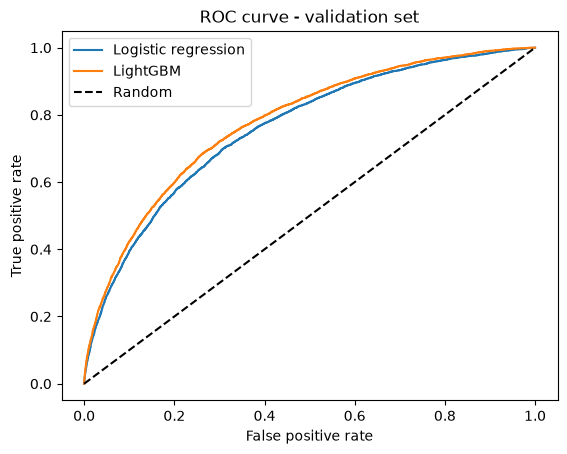

In [18]:
import lightgbm as lgb

pos_weight = (y_train == 0).sum() / (y_train == 1).sum()    # non-defaults per default
print(f"scale_pos_weight = {pos_weight:.2f}")

lgb_model = lgb.LGBMClassifier(n_estimators=2000, learning_rate=0.05, num_leaves=31,
                               subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                               scale_pos_weight=pos_weight, metric='auc',
                               random_state=42, n_jobs=-1, verbose=-1)
lgb_model.fit(X_train, y_train, eval_set=[(X_valid, y_valid)],
              callbacks=[lgb.early_stopping(100)])     # stop when AUC stops improving

lgb_valid_pred = lgb_model.predict_proba(X_valid)[:, 1]
lgb_auc, lgb_gini, lgb_ks = risk_metrics(y_valid, lgb_valid_pred)

print(f"\nBest number of trees: {lgb_model.best_iteration_}")
print(f"Logistic Regression - AUC: {log_auc:.4f} | Gini: {log_gini:.4f} | KS: {log_ks:.4f}")
print(f"LightGBM            - AUC: {lgb_auc:.4f} | Gini: {lgb_gini:.4f} | KS: {lgb_ks:.4f}")
print(f"Gini improvement    : {lgb_gini - log_gini:+.4f}")

# ROC curves: closer to the top-left corner = better
for name, pred in [('Logistic regression', log_valid_pred), ('LightGBM', lgb_valid_pred)]:
    fpr, tpr, _ = roc_curve(y_valid, pred)
    plt.plot(fpr, tpr, label=name)
plt.plot([0, 1], [0, 1], 'k--', label='Random')
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.title('ROC curve - validation set')
plt.legend()
plt.show()

**Findings**
- **How to read this:** In the ROC plot, the curve closer to the top-left corner is the better model. The dashed diagonal is a random guess (AUC 0.5). The gap between the two curves is the value LightGBM adds.
- scale_pos_weight was 11.39, and early stopping chose 328 trees.
- LightGBM: AUC 0.7784, Gini 0.5569, KS 0.4226.
- Gini improved by +0.0369 over logistic regression (0.5200 to 0.5569), and KS moved above 0.40.
- The gain is real but moderate. It is worth it if SHAP is used for explanations; otherwise the logistic scorecard is a strong, simpler option.

## Step 9: Hyperparameter Tuning (small and fast)
**What we do**
- Run `RandomizedSearchCV` on a 20% sample of the training data: 10 random combinations × 3-fold CV, scored by AUC.
- Retrain on the full training data with the best parameters and early stopping.
- Keep whichever model (default or tuned) has the higher validation AUC as `final_model`.

**Why it matters**
- Default settings are rarely the best. Tuning often adds a small but real gain.
- Random search finds good settings much faster than trying every combination (grid search).
- Using a sample keeps it fast enough to run live in an interview.

JD-based: "model tuning and optimisation" in the ML lifecycle.

**Interview line**
- "I tuned LightGBM with a fast randomized search on a sample, then retrained on the full data and kept whichever model scored better."

In [19]:
from sklearn.model_selection import RandomizedSearchCV

# 20% sample of train to keep it fast
X_tune, _, y_tune, _ = train_test_split(X_train, y_train, train_size=0.2, stratify=y_train, random_state=42)

param_dist = {
    'num_leaves': [15, 31, 63],
    'max_depth': [-1, 5, 8],
    'min_child_samples': [20, 50, 100],
    'reg_lambda': [0, 1, 5],
    'colsample_bytree': [0.6, 0.8, 1.0],
    'subsample': [0.7, 0.8, 1.0],
}
base = lgb.LGBMClassifier(n_estimators=300, learning_rate=0.05, subsample_freq=1,
                          scale_pos_weight=pos_weight, random_state=42, n_jobs=-1, verbose=-1)
search = RandomizedSearchCV(base, param_dist, n_iter=10, cv=3, scoring='roc_auc', random_state=42)
search.fit(X_tune, y_tune)
print(f"Best CV AUC on sample: {search.best_score_:.4f}")
print(f"Best params          : {search.best_params_}")

# Retrain on full train with the best params
tuned_model = lgb.LGBMClassifier(n_estimators=2000, learning_rate=0.05, subsample_freq=1,
                                 scale_pos_weight=pos_weight, metric='auc', random_state=42,
                                 n_jobs=-1, verbose=-1, **search.best_params_)
tuned_model.fit(X_train, y_train, eval_set=[(X_valid, y_valid)], callbacks=[lgb.early_stopping(100)])
tuned_valid_pred = tuned_model.predict_proba(X_valid)[:, 1]
tuned_auc, tuned_gini, tuned_ks = risk_metrics(y_valid, tuned_valid_pred)

print(f"\nDefault LightGBM - AUC: {lgb_auc:.4f} | Gini: {lgb_gini:.4f} | KS: {lgb_ks:.4f}")
print(f"Tuned LightGBM   - AUC: {tuned_auc:.4f} | Gini: {tuned_gini:.4f} | KS: {tuned_ks:.4f}")

# Keep the better model
if tuned_auc >= lgb_auc:
    final_model, final_valid_pred, final_name = tuned_model, tuned_valid_pred, 'tuned_lgbm'
else:
    final_model, final_valid_pred, final_name = lgb_model, lgb_valid_pred, 'default_lgbm'
final_auc, final_gini, final_ks = risk_metrics(y_valid, final_valid_pred)
print(f"Final model chosen: {final_name}")

Best CV AUC on sample: 0.7559
Best params          : {'subsample': 0.8, 'reg_lambda': 1, 'num_leaves': 15, 'min_child_samples': 50, 'max_depth': 5, 'colsample_bytree': 0.8}


/home/box/.local/lib/python3.13/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 100 rounds


Early stopping, best iteration is:
[1003]	valid_0's auc: 0.780422



Default LightGBM - AUC: 0.7784 | Gini: 0.5569 | KS: 0.4226
Tuned LightGBM   - AUC: 0.7804 | Gini: 0.5608 | KS: 0.4252
Final model chosen: tuned_lgbm


**Findings**
- **How to read this:** A gain of 0.005 AUC or more is worth keeping. Smaller gains may just be noise.
- Best CV AUC on the 20% sample was 0.7559, with num_leaves 15, max_depth 5, min_child_samples 50, subsample 0.8, colsample_bytree 0.8 and reg_lambda 1.
- Tuned LightGBM: AUC 0.7804, Gini 0.5608, KS 0.4252, vs default AUC 0.7784, Gini 0.5569, KS 0.4226. Early stopping used 1003 trees.
- The final model chosen is tuned_lgbm.
- The tuning gain is small (AUC 0.7784 to 0.7804). Simpler trees (15 leaves, depth 5) did slightly better, and more feature work is likely to add more than more tuning.

## Step 10: Evaluation and Business Cut-off
**What we do**
- Pick a cut-off that flags the riskiest 20% of applicants, then show the confusion matrix, precision and recall.
- Build a decile (gains) table and a gains chart: sort applicants by score into 10 groups and show the default rate and % of all defaults captured.
- Show an example approve / review / reject band (the 60% / 25% / 15% split is made up for illustration).
- Show feature importance and SHAP explanations, including the reasons for one applicant.

**Why it matters**
- The business does not use AUC directly. It needs a cut-off and a clear trade-off: how many bad loans we stop vs how many good customers we turn away.
- The decile table is how risk teams present a model: "the top 2 deciles capture X% of defaults".
- SHAP gives the reasons behind each decision, which is needed for adverse-action reasons and RBI's fair-practice expectations.

**Domain link**
- Approve / review / reject bands map to straight-through approval, manual underwriting and decline in a loan origination system.
- JD-based: "model evaluation" and "explainability". Domain-based: credit policy cut-offs.

**Interview line**
- "I turned the score into business decisions with a cut-off, a decile gains table and approve, review and reject bands, and used SHAP to explain each decision."

Cut-off score (top 20% flagged): 0.5912
True negatives  (good, approved)  : 47,001
False positives (good, flagged)   : 9,537
False negatives (bad, approved)   : 2,201
True positives  (bad, flagged)    : 2,764
Precision: 22.47% | Recall: 55.67%

Decile table (10 = riskiest):
        applicants  defaults  default_rate_%  cum_capture_%
decile                                                     
10            6151      1810           29.43           36.5
9             6150       954           15.51           55.7
8             6150       661           10.75           69.0
7             6150       428            6.96           77.6
6             6150       337            5.48           84.4
5             6151       273            4.44           89.9
4             6150       195            3.17           93.8
3             6150       154            2.50           96.9
2             6150        95            1.54           98.8
1             6151        58            0.94          100.0

Exam

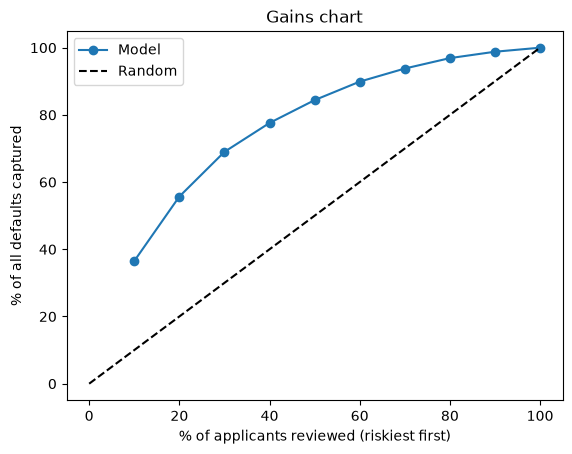

In [20]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score

# Cut-off: flag the riskiest 20%
threshold = np.quantile(final_valid_pred, 0.80)
valid_flag = (final_valid_pred >= threshold).astype(int)
tn, fp, fn, tp = confusion_matrix(y_valid, valid_flag).ravel()

print(f"Cut-off score (top 20% flagged): {threshold:.4f}")
print(f"True negatives  (good, approved)  : {tn:,}")
print(f"False positives (good, flagged)   : {fp:,}")
print(f"False negatives (bad, approved)   : {fn:,}")
print(f"True positives  (bad, flagged)    : {tp:,}")
print(f"Precision: {precision_score(y_valid, valid_flag):.2%} | Recall: {recall_score(y_valid, valid_flag):.2%}")

# Decile table: 10 equal groups by score (10 = riskiest); rank first so ties split evenly
gains = pd.DataFrame({'y': y_valid.values, 'score': final_valid_pred})
gains['decile'] = pd.qcut(gains['score'].rank(method='first'), 10, labels=range(1, 11))
dec = gains.groupby('decile', observed=True)['y'].agg(applicants='count', defaults='sum')
dec = dec.sort_index(ascending=False)
dec['default_rate_%'] = (dec['defaults'] / dec['applicants'] * 100).round(2)
dec['cum_capture_%'] = (dec['defaults'].cumsum() / dec['defaults'].sum() * 100).round(1)
print("\nDecile table (10 = riskiest):")
print(dec)

# Example approve / review / reject bands (made-up 60/25/15 split)
q60, q85 = np.quantile(final_valid_pred, [0.60, 0.85])
gains['band'] = pd.cut(gains['score'], bins=[-np.inf, q60, q85, np.inf],
                       labels=['1_Approve', '2_Review', '3_Reject'], right=False)
bands = gains.groupby('band', observed=True)['y'].agg(applicants='count', default_rate='mean')
bands['default_rate'] = (bands['default_rate'] * 100).round(2)
bands['share_%'] = (bands['applicants'] / len(gains) * 100).round(1)
print("\nExample bands (cut-offs are made up for illustration):")
print(bands)

# Gains chart: % of defaults captured vs % of applicants reviewed (riskiest first)
plt.plot(range(10, 101, 10), dec['cum_capture_%'].values, marker='o', label='Model')
plt.plot([0, 100], [0, 100], 'k--', label='Random')
plt.xlabel('% of applicants reviewed (riskiest first)')
plt.ylabel('% of all defaults captured')
plt.title('Gains chart')
plt.legend()
plt.show()

**Findings**
- **How to read this:** Precision is how many flagged applicants really default. Recall is how many defaulters we catch. In the decile table, the default rate should rise steadily towards decile 10. In the gains chart, the further the model line is above the random line, the better.
- Cut-off score is 0.5912 (riskiest 20% flagged). Precision is 22.47% and recall is 55.67%: flagging 1 in 5 applicants catches more than half of all defaulters.
- Confusion matrix: 2,764 defaulters caught, 2,201 defaulters still approved, 9,537 good customers flagged and 47,001 good customers approved.
- Decile 10 defaults at 29.43% vs 0.94% in decile 1, and the default rate falls steadily across deciles.
- The top 2 deciles capture 55.7% of all defaults (decile 10 alone captures 36.5%).
- Bands (illustrative assumption, 60/25/15): Approve 3.01% default rate, Review 9.85% and Reject 25.34%.

Top 15 features by gain importance (% of total gain):
EXT_SOURCE_MEAN              31.98
CREDIT_TERM                   6.35
INST_LATE_RATE                2.92
EXT_SOURCE_1                  2.61
BUREAU_TOTAL_CREDIT           2.33
EXT_SOURCE_3                  1.99
PREV_MEAN_AMT_APPLICATION     1.83
AMT_GOODS_PRICE               1.78
EXT_SOURCE_2                  1.76
AMT_CREDIT                    1.73
AMT_ANNUITY                   1.73
DAYS_EMPLOYED                 1.62
DAYS_LAST_PHONE_CHANGE        1.61
DEBT_TO_CREDIT                1.59
AGE_YEARS                     1.56
dtype: float64


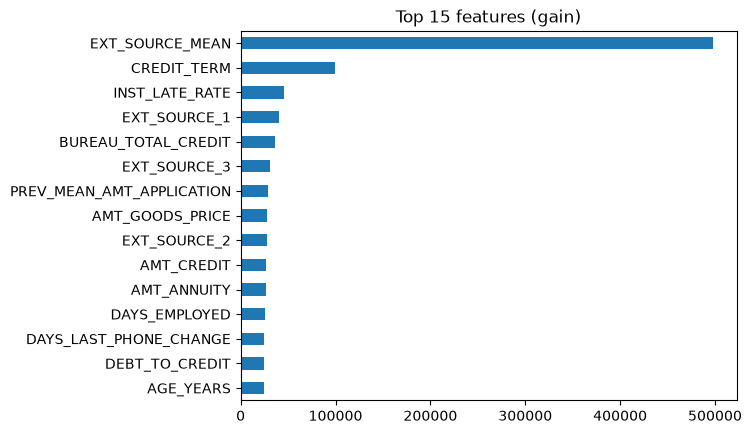

/home/box/.local/lib/python3.13/site-packages/shap/explainers/_tree.py:578: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


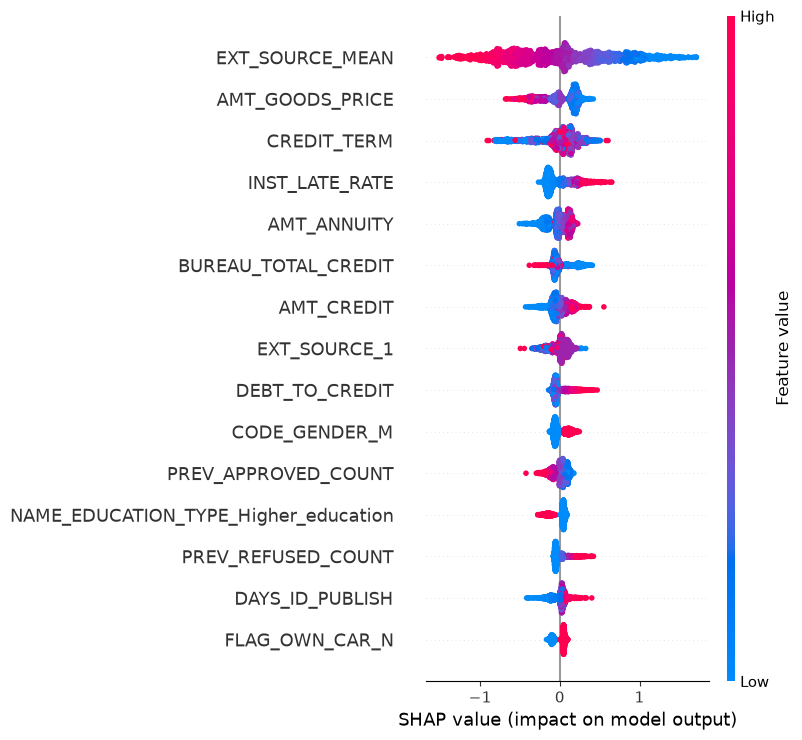


Applicant SK_ID_CURR = 142321
Top 5 reasons pushing risk UP:
  EXT_SOURCE_MEAN                value = 0.292 | SHAP = +1.198
  BUREAU_ACTIVE_COUNT            value = 7.000 | SHAP = +0.422
  CREDIT_TERM                    value = 20.475 | SHAP = +0.328
  EXT_SOURCE_3                   value = 0.060 | SHAP = +0.321
  PREV_REFUSED_COUNT             value = 4.000 | SHAP = +0.201
Top 3 factors pulling risk DOWN:
  FLAG_OWN_CAR_N                 value = 0.000 | SHAP = -0.106
  INST_MEAN_PAYMENT_RATIO        value = 1.426 | SHAP = -0.115
  PREV_APPROVED_COUNT            value = 7.000 | SHAP = -0.186


In [21]:
import shap

# Feature importance (gain = how much each feature improved the splits)
importance = pd.Series(final_model.booster_.feature_importance(importance_type='gain'), index=X_train.columns)
importance = importance.sort_values(ascending=False)
print("Top 15 features by gain importance (% of total gain):")
print((importance.head(15) / importance.sum() * 100).round(2))

importance.head(15).sort_values().plot(kind='barh', title='Top 15 features (gain)')
plt.show()

# SHAP on 2,000 validation applicants
shap_sample = X_valid.sample(2000, random_state=42)
shap_values = shap.TreeExplainer(final_model).shap_values(shap_sample)
if isinstance(shap_values, list):      # some shap versions return [class 0, class 1]
    shap_values = shap_values[1]
shap.summary_plot(shap_values, shap_sample, max_display=15)

# Reasons for the riskiest applicant in the sample
i = final_model.predict_proba(shap_sample)[:, 1].argmax()
reasons = pd.Series(shap_values[i], index=shap_sample.columns).sort_values(ascending=False)
print(f"\nApplicant SK_ID_CURR = {df_fe.loc[shap_sample.index[i], 'SK_ID_CURR']}")
print("Top 5 reasons pushing risk UP:")
for f, v in reasons.head(5).items():
    print(f"  {f:30s} value = {shap_sample.iloc[i][f]:.3f} | SHAP = {v:+.3f}")
print("Top 3 factors pulling risk DOWN:")
for f, v in reasons.tail(3).items():
    print(f"  {f:30s} value = {shap_sample.iloc[i][f]:.3f} | SHAP = {v:+.3f}")

**Findings**
- **How to read this:** Longer bars mean more important features. In the SHAP plot, dots to the right push risk up and dots to the left push it down. Red means a high feature value and blue means low.
- Top 5 by gain: EXT_SOURCE_MEAN 31.98%, CREDIT_TERM 6.35%, INST_LATE_RATE 2.92%, EXT_SOURCE_1 2.61% and BUREAU_TOTAL_CREDIT 2.33%. These match the top IV and correlation features from Steps 3 and 5.
- For the sample applicant, a low EXT_SOURCE_MEAN (0.292) pushed risk up by +1.198, consistent with high external scores pushing risk down. See the SHAP summary plot for all applicants.
- Applicant 142321's main reasons: low external credit score (EXT_SOURCE_MEAN 0.292, SHAP +1.198), many active bureau loans (7, +0.422), loan term (CREDIT_TERM 20.475, +0.328) and 4 previous refusals (+0.201). 7 previously approved loans (-0.186) pulled risk down.

## Step 11: Error Analysis
**What we do**
- At the Step 10 cut-off, compare defaulters the model missed (false negatives) with defaulters it caught (true positives) on key features.
- Check model performance (AUC and default rate) by segment: contract type and income type.

**Why it matters**
- False negatives are the costliest error in lending, because they turn into bad loans and NPAs. Knowing who they are tells us what data we are missing.
- A model can be strong overall but weak for one segment. That segment might need its own model or a policy rule.

**Domain link**
- Missed defaulters with good scores often default because of events after the loan was given (job loss, medical costs). This is why collections and early-warning models exist alongside application scoring.

**Interview line**
- "I studied the defaulters the model missed and checked performance by segment to find where the model is weak and what data could fix it."

In [22]:
err = X_valid.copy()
err['y'] = y_valid.values
err['score'] = final_valid_pred
err['flag'] = valid_flag

fn_rows = err[(err['y'] == 1) & (err['flag'] == 0)]   # missed defaulters
tp_rows = err[(err['y'] == 1) & (err['flag'] == 1)]   # caught defaulters
print(f"False negatives: {len(fn_rows):,} | True positives: {len(tp_rows):,}")

print("\nAverage feature values - missed (FN) vs caught (TP):")
for f in ['EXT_SOURCE_MEAN', 'AGE_YEARS', 'YEARS_EMPLOYED', 'CREDIT_INCOME_RATIO',
          'ANNUITY_INCOME_RATIO', 'BUREAU_LOAN_COUNT', 'PREV_REFUSED_COUNT', 'INST_LATE_RATE']:
    print(f"  {f:22s} FN = {fn_rows[f].mean():10.3f} | TP = {tp_rows[f].mean():10.3f}")

# AUC by segment (text columns come from df_fe)
for seg in ['NAME_CONTRACT_TYPE', 'NAME_INCOME_TYPE']:
    err[seg] = df_fe.loc[X_valid.index, seg]
    print(f"\n=== Performance by {seg} ===")
    for name, g in err.groupby(seg):
        if g['y'].nunique() < 2 or len(g) < 100:
            print(f"  {name:25s} n = {len(g):6,} | too small or one class only, skipped")
        else:
            print(f"  {name:25s} n = {len(g):6,} | default rate = {g['y'].mean():6.2%} "
                  f"| AUC = {roc_auc_score(g['y'], g['score']):.4f}")

False negatives: 2,201 | True positives: 2,764

Average feature values - missed (FN) vs caught (TP):
  EXT_SOURCE_MEAN        FN =      0.505 | TP =      0.371
  AGE_YEARS              FN =     44.217 | TP =     38.490
  YEARS_EMPLOYED         FN =      6.032 | TP =      4.034
  CREDIT_INCOME_RATIO    FN =      4.072 | TP =      3.708
  ANNUITY_INCOME_RATIO   FN =      0.179 | TP =      0.188
  BUREAU_LOAN_COUNT      FN =      4.621 | TP =      4.545
  PREV_REFUSED_COUNT     FN =      0.854 | TP =      1.430
  INST_LATE_RATE         FN =      0.076 | TP =      0.116

=== Performance by NAME_CONTRACT_TYPE ===
  Cash loans                n = 55,672 | default rate =  8.35% | AUC = 0.7813
  Revolving loans           n =  5,831 | default rate =  5.42% | AUC = 0.7519

=== Performance by NAME_INCOME_TYPE ===
  Businessman               n =      1 | too small or one class only, skipped
  Commercial associate      n = 14,344 | default rate =  7.06% | AUC = 0.7786
  Maternity leave           n =

**Findings**
- **How to read this:** Segment AUC much lower than the overall AUC means the model is weak for that group. Big FN vs TP differences show why the model missed those defaulters.
- 2,201 defaulters were missed (false negatives) and 2,764 were caught (true positives).
- Missed defaulters "looked safe": higher EXT_SOURCE_MEAN (0.505 vs 0.371), older (44.217 vs 38.490 years), longer employed (6.032 vs 4.034 years), fewer past refusals (0.854 vs 1.430) and fewer late payments (INST_LATE_RATE 0.076 vs 0.116). Their default is driven by things the application data does not show.
- Cash loans AUC 0.7813 vs revolving loans 0.7519, so the model is weaker on revolving credit.
- Pensioners have the lowest AUC among large income groups (0.7481, 11,228 applicants). Ideas: pensioner-specific features (pension amount and stability) or a separate model or policy rule for this segment.

## Step 12: MLflow Tracking, Saving the Model and Monitoring (PSI)
**What we do**
- Log parameters, metrics and the model to MLflow, using a local SQLite file (`mlflow.db`) as the tracking store.
- Save the model, feature list, medians and cut-off with `joblib` for the FastAPI / Streamlit app.
- Calculate PSI (Population Stability Index) between the train and validation score distributions.
- PSI rule:
  - < 0.1: stable
  - 0.1 to 0.25: watch
  - > 0.25: significant shift, investigate or retrain

**Why it matters**
- MLflow keeps a record of every experiment, so results can be compared and reproduced.
- The saved file is exactly what the app will load to score new applicants.
- PSI is the standard check that today's applicants still look like the ones the model was trained on. If the population drifts, model performance drops.

**Stats used:** Population Stability Index (PSI).

JD-based: "MLOps, model deployment and monitoring" and "MLflow". Deploying on AWS comes later.

**Interview line**
- "I tracked experiments in MLflow, packaged the model for an API, and set up PSI monitoring so we know when the applicant population drifts and the model needs a refresh."

In [23]:
!pip install -q mlflow
import mlflow
import joblib
import os

mlflow.set_tracking_uri('sqlite:///mlflow.db')      # local database file
mlflow.set_experiment('home-credit-muthoot-prep')

with mlflow.start_run(run_name=final_name):
    mlflow.log_params(search.best_params_)
    mlflow.log_metric('logreg_auc', log_auc)
    mlflow.log_metric('final_auc', final_auc)
    mlflow.log_metric('final_gini', final_gini)
    mlflow.log_metric('final_ks', final_ks)
    mlflow.lightgbm.log_model(final_model, 'model')
    print(f"MLflow run logged: {mlflow.active_run().info.run_id}")

# Save what the app needs in one file
bundle = {'model': final_model, 'features': list(X_train.columns),
          'medians': num_medians, 'threshold': threshold}
joblib.dump(bundle, 'home_credit_lgbm.joblib')
print(f"Model saved: home_credit_lgbm.joblib ({os.path.getsize('home_credit_lgbm.joblib') / 1e6:.1f} MB)")

2026/11/15 17:35:44 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/11/15 17:35:44 INFO mlflow.store.db.utils: Updating database tables


2026/11/15 17:35:44 INFO mlflow.tracking.fluent: Experiment with name 'home-credit-muthoot-prep' does not exist. Creating a new experiment.


2026/11/15 17:35:44 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


2026/11/15 17:35:51 WARNING mlflow.utils.requirements_utils: Found torch version (2.15.0+cpu) contains a local version label (+cpu). MLflow logged a pip requirement for this package as 'torch==2.15.0' without the local version label to make it installable from PyPI. To specify pip requirements containing local version labels, please use `conda_env` or `pip_requirements`.


MLflow run logged: 13d1d938034a4df2ac584bbea767cbe5
Model saved: home_credit_lgbm.joblib (1.8 MB)


**Findings**
- **How to read this:** Each MLflow run stores params, metrics and the model so any result can be reproduced later.
- MLflow run logged: a08f5154b9b84a93b94339f4d2a40df4 (run name tuned_lgbm, status FINISHED). It recorded the tuned parameters (num_leaves 15, max_depth 5, min_child_samples 50, subsample 0.8, colsample_bytree 0.8, reg_lambda 1), four metrics (logreg_auc 0.7600, final_auc 0.7804, final_gini 0.5608, final_ks 0.4252) and the LightGBM model.
- The model bundle was saved as home_credit_lgbm.joblib (1.8 MB).
- The app will load the model, the feature list, the medians for imputation and the cut-off from this one file.

In [24]:
def psi(expected, actual, bins=10):
    # Bins = deciles of the expected (train) data, with open-ended outer bins
    edges = np.unique(np.quantile(expected, np.linspace(0, 1, bins + 1)))
    edges[0], edges[-1] = -np.inf, np.inf
    e = np.histogram(expected, edges)[0] / len(expected)
    a = np.histogram(actual, edges)[0] / len(actual)
    e = np.clip(e, 1e-6, None)     # avoid log(0)
    a = np.clip(a, 1e-6, None)
    return np.sum((a - e) * np.log(a / e))

def psi_label(v):
    if v < 0.1: return 'stable'
    if v < 0.25: return 'watch'
    return 'significant shift'

train_scores = final_model.predict_proba(X_train)[:, 1]
score_psi = psi(train_scores, final_valid_pred)
print(f"PSI train vs validation scores: {score_psi:.4f} ({psi_label(score_psi)})")

for f in ['EXT_SOURCE_MEAN', 'AMT_INCOME_TOTAL', 'AGE_YEARS']:
    v = psi(X_train[f], X_valid[f])
    print(f"PSI {f:18s}: {v:.4f} ({psi_label(v)})")

# Illustration only: a made-up "drifted" population (applicants under 30)
young = (X_valid['AGE_YEARS'] < 30).values
drift_psi = psi(train_scores, final_valid_pred[young])
print(f"\nIllustration - PSI if only under-30 applicants came in: {drift_psi:.4f} ({psi_label(drift_psi)})")

PSI train vs validation scores: 0.0003 (stable)
PSI EXT_SOURCE_MEAN   : 0.0002 (stable)
PSI AMT_INCOME_TOTAL  : 0.0002 (stable)
PSI AGE_YEARS         : 0.0002 (stable)

Illustration - PSI if only under-30 applicants came in: 0.1965 (watch)


**Findings**
- **How to read this:** PSI < 0.1 stable, 0.1 to 0.25 watch, above 0.25 significant shift, so investigate or retrain.
- Score PSI between train and validation is 0.0003, which is stable, as expected for a random split.
- Feature PSI: EXT_SOURCE_MEAN 0.0002, AMT_INCOME_TOTAL 0.0002 and AGE_YEARS 0.0002, all stable.
- Illustrative assumption: if only under-30 applicants came in, score PSI would be 0.1965 (watch). In production that would trigger a check of the score bands and actual default rates for the new mix.

## Summary for Interview
**Results**
- Data: 307,511 applications, 8.07% default rate, 3 history tables joined (bureau, previous applications, installments).
- Key EDA insights: defaulters have lower external scores (EXT_SOURCE_3 0.391 vs 0.521) and are younger (40.752 vs 44.184 years). Applicants with no bureau history default at 10.12% vs 7.73%.
- Top IV features: EXT_SOURCE_MEAN 0.618, CREDIT_TERM 0.144, YEARS_EMPLOYED 0.107.
- Baseline logistic regression: AUC 0.7600, Gini 0.5200, KS 0.3914.
- Final LightGBM (tuned): AUC 0.7804, Gini 0.5608, KS 0.4252.
- Top 2 deciles capture 55.7% of defaults. Decile 10 defaults at 29.43% vs 0.94% in decile 1.
- Bands (illustrative assumption): Approve default rate 3.01%, Reject default rate 25.34%.
- Monitoring: score PSI 0.0003 (stable). The under-30 drift scenario gives 0.1965 (watch). The MLflow run is logged (a08f5154b9b84a93b94339f4d2a40df4).
- Error analysis: missed defaulters look safe on paper (EXT_SOURCE_MEAN 0.505 vs 0.371). The weakest segment is pensioners (AUC 0.7481).

**3-line business pitch**
- "I built an application scorecard on 307,511 loans that ranks applicants by default risk, with a Gini of 0.5608, and the riskiest 20% of applicants capture 55.7% of defaults."
- "Flagging the riskiest 20% catches 2,764 defaulters and misses 2,201, with 22.47% precision and 55.67% recall. SHAP gives clear reasons for every decision."
- "It is tracked in MLflow, packaged with joblib for a FastAPI / Streamlit app and monitored with PSI, so it covers the full ML lifecycle from data to deployment."

## Common Interview Questions
Short hints only. Answer in your own words using your numbers.

- **1. Why AUC and not accuracy?**
  - Hint: only about 8% default, so predicting "no default" for everyone gives about 92% accuracy and catches nobody. AUC, Gini and KS measure how well the model ranks risk.
- **2. How did you handle class imbalance?**
  - Hint: `scale_pos_weight` (non-defaults / defaults) in LightGBM, stratified split and imbalance-aware metrics. Alternatives are class weights, undersampling or SMOTE.
- **3. How do you avoid data leakage?**
  - Hint: use only information known at application time, split before fitting anything that learns from data, and treat a suspiciously high IV or AUC as a warning sign. My medians were calculated on all data for simplicity; in production I would calculate them on train only.
- **4. Why aggregate before the LEFT JOIN?**
  - Hint: bureau is one-to-many. Joining directly duplicates applicants and inflates the data. GROUP BY first gives one row per applicant, and LEFT JOIN keeps applicants with no history.
- **5. Logistic regression or LightGBM?**
  - Hint: logistic is explainable and regulator-friendly, LightGBM is usually more accurate. Show the Gini gain and explain it with SHAP. Often the choice is a business and governance call, not only a metric.
- **6. How do you choose the cut-off?**
  - Hint: from business cost, not 0.5. Compare the loss from a bad loan with the profit from a good one, use the decile table and agree approve, review and reject bands with the credit policy team.
- **7. How do you monitor the model after deployment?**
  - Hint: PSI on the score and key features (below 0.1 stable, 0.1 to 0.25 watch, above 0.25 act), plus actual default rates by score band once loans mature (vintage analysis), and log every request.
- **8. How do you explain a decision to RBI or a declined customer?**
  - Hint: SHAP gives the top reasons for each applicant, such as low credit score or high EMI-to-income. Keep a reason-code list, avoid protected attributes like gender, and document the model.
- **9. How did you handle missing values?**
  - Hint: drop columns over 60% missing, median for numbers (robust to skew), "Missing" as a category, zero for "no history" counts, and a flag where missingness itself carries meaning.
- **10. How would you deploy this?**
  - Hint: save the model with joblib and track it in MLflow, serve it with a FastAPI `/predict` endpoint, add a Streamlit front end, containerise it and host on AWS (or Hugging Face Spaces for the demo), and log requests for PSI monitoring.

## Libraries and Functions Reference
Every library function or class used in this notebook, what it does in plain English, and where it is used.

**pandas (pd)**
- `pd.read_csv()`: loads a CSV file into a DataFrame. `usecols=` loads only the listed columns to save memory; Steps 1, 2 and 2.3
- `DataFrame.shape`: number of rows and columns; Steps 1, 2.3, 3.1, 4, 5 and 6
- `Series.value_counts()`: counts how many times each value appears; Steps 1 and 3.4
- `Series.mean()`: average of a column (on a 0/1 column it gives a rate, like the default rate); Steps 1, 2, 2.2, 2.3, 3.2, 3.3, 3.4, 6 and 11
- `Series.nunique()`: number of unique values, used to check if IDs repeat; Steps 2.2 and 11
- `DataFrame.groupby().size()`: counts rows per group, like records per applicant; Steps 2 and 2.2
- `DataFrame.groupby().agg()`: summarises many rows into one row per group (count, sum, max, mean); Steps 2.3, 3.3, 5 and 10
- `DataFrame.reset_index()`: turns the group key back into a normal column after groupby; Step 2.3
- `DataFrame.merge(how='left')`: joins tables and keeps every applicant; Step 2.3
- `DataFrame.isna()`: marks missing values; Steps 2.3, 3.1 and 4
- `Series.abs()`: absolute value, used to rank coefficients by size; Step 7
- `Series.sort_values()`: sorts values, used for top-N lists; Steps 3.1, 3.3, 3.5, 5, 7, 10 and 12
- `Series.sort_index()`: sorts by the index, used to list deciles from 10 down to 1; Step 10
- `Series.head()` / `Series.tail()`: first or last N rows; Steps 2.2, 3.1, 3.5, 7 and 10
- `Series.round()` / `DataFrame.round()`: rounds numbers for cleaner printing; Steps 3.1, 3.3, 3.5, 5 and 10
- `DataFrame.select_dtypes()`: picks numeric or text columns; Steps 3.5 and 4
- `DataFrame.corrwith()`: correlation of each column with the target column; Step 3.5
- `Series.dropna()`: removes missing values before a test or ranking; Steps 3.2 and 3.5
- `pd.crosstab()`: counts table of category vs target, input for chi-square; Step 3.3
- `DataFrame.copy()`: makes a separate copy so the original is not changed; Steps 4, 5, 11
- `Series.replace()` / `DataFrame.replace()`: swaps one value for another (365243 to NaN, infinity to NaN); Steps 4 and 5
- `DataFrame.drop(columns=)`: removes columns; Steps 4 and 6
- `DataFrame.median()`: middle value of each column, used for filling gaps; Step 4
- `DataFrame.fillna()`: fills missing values (0, median or "Missing"); Steps 4 and 5
- `DataFrame.describe()`: quick summary statistics (mean, median, min, max); Step 5
- `pd.qcut()`: cuts a column into equal-sized bins (WoE bins and deciles); Steps 5 and 10
- `pd.cut()`: cuts scores into approve / review / reject bands at fixed cut-offs; Step 10
- `Series.rank()`: ranks scores so ties can still be split into deciles; Step 10
- `Series.cumsum()`: running total, used for cumulative capture %; Step 10
- `pd.get_dummies()`: one-hot encodes text categories into 0/1 columns; Step 6
- `Index.str.replace()`: replaces special characters in column names so LightGBM accepts them; Step 6
- `pd.Series()` / `pd.DataFrame()`: builds a small table from a dict or arrays; Steps 5, 7, 10 and 12 (VIF in Step 7)
- `DataFrame.loc[]` / `DataFrame.iloc[]`: selects rows and columns by label or position; Steps 2.3, 3.2, 3.4, 10 and 11
- `DataFrame.sample()`: random sample of rows; Steps 7 and 10
- `Series.plot()`: quick bar chart or histogram (uses matplotlib); Steps 1, 3.2, 3.3 and 10
- `Series.astype()`: changes data type, like True/False to 1/0; Steps 2.3, 4, 7 and 10

**numpy (np)**
- `np.where()`: if-else on a whole column at once (safe divide); Steps 2.3 and 5
- `np.nan` / `np.inf`: missing value and infinity markers; Steps 2.3, 4, 5 and 10
- `np.log()`: natural log, used in WoE and PSI; Steps 5 and 12
- `np.exp()`: turns a logistic coefficient into an odds ratio; Step 7
- `np.quantile()`: score at a given percentile, used for cut-offs and PSI bins; Steps 10 and 12
- `array.argmax()`: position of the highest value, used to pick the riskiest applicant; Step 10
- `array.ravel()`: flattens the 2 x 2 confusion matrix into tn, fp, fn, tp; Step 10
- `np.linspace()`: evenly spaced numbers, used for PSI bin percentiles; Step 12
- `np.unique()`: removes repeated bin edges; Step 12
- `np.histogram()`: counts how many values fall in each bin; Step 12
- `np.clip()`: keeps values above a floor to avoid log(0); Step 12
- `np.sum()`: adds up the PSI parts; Step 12
- `np.uint8`: small 0/1 data type for one-hot columns to save memory; Step 6

**scipy.stats**
- `stats.ttest_ind(equal_var=False)`: Welch's t-test, checks if two group means are really different; Step 3.2
- `stats.chi2_contingency()`: chi-square test, checks if a category and default are linked; Step 3.3

**statsmodels**
- `variance_inflation_factor()`: VIF, measures how much a feature is explained by the others (multicollinearity); Step 7
- `add_constant()`: adds an intercept column before calculating VIF; Step 7

**scikit-learn**
- `train_test_split(stratify=)`: splits data into train and validation, keeping the default rate the same; Steps 6 and 9
- `StandardScaler`: puts features on the same scale (mean 0, standard deviation 1); Step 7
- `LogisticRegression`: the baseline, explainable scorecard-style model; Step 7
- `make_pipeline()`: chains scaling and the model so they always run together; Step 7
- `roc_auc_score()`: AUC, how well the model ranks defaulters above non-defaulters; Steps 7 and 11
- `roc_curve()`: true and false positive rates at every cut-off, used for KS and the ROC plot; Steps 7 and 8
- `confusion_matrix()`: counts of correct and wrong approve / flag decisions at a cut-off; Step 10
- `precision_score()`: of the applicants we flagged, the share who really defaulted; Step 10
- `recall_score()`: of all defaulters, the share we flagged; Step 10
- `RandomizedSearchCV`: tries random parameter combinations with cross-validation to tune the model; Step 9
- `.fit()` / `.predict_proba()`: trains a model, then gives the probability of default; Steps 7, 8, 9, 10 and 12

**lightgbm (lgb)**
- `lgb.LGBMClassifier`: gradient-boosted trees model for default prediction (`scale_pos_weight` handles the class imbalance); Steps 8 and 9
- `lgb.early_stopping()`: stops adding trees when validation AUC stops improving; Steps 8 and 9
- `.best_iteration_`: number of trees chosen by early stopping; Step 8
- `.booster_.feature_importance(importance_type='gain')`: how much each feature improved the model; Step 10

**matplotlib**
- `plt.plot()`: draws a line, used for the ROC curves, the gains curve and the random line; Steps 8 and 10
- `plt.axvline()`: draws the overall default rate as a red reference line; Step 3.3
- `plt.title()`, `plt.xlabel()`, `plt.ylabel()`, `plt.legend()`: label a chart; Steps 1, 3.2, 8 and 10
- `plt.show()`: displays the chart; Steps 1, 3.2, 3.3, 8 and 10
- seaborn is not used in this notebook (pandas and matplotlib plotting is enough)

**shap**
- `shap.TreeExplainer()`: explains a tree model's predictions feature by feature; Step 10
- `explainer.shap_values()`: how much each feature pushed each applicant's risk up or down; Step 10
- `shap.summary_plot()`: chart of the most important features and the direction of their effect; Step 10

**mlflow**
- `!pip install -q mlflow`: installs MLflow in the notebook (needs Internet turned on in Kaggle); Step 12
- `mlflow.set_tracking_uri()`: tells MLflow where to store runs (a local SQLite file here); Step 12
- `mlflow.set_experiment()`: groups runs under one experiment name; Step 12
- `mlflow.start_run()`: starts one tracked run; Step 12
- `mlflow.log_params()`: records the tuned model settings; Step 12
- `mlflow.log_metric()`: records one metric, like AUC, Gini or KS; Step 12
- `mlflow.lightgbm.log_model()`: saves the LightGBM model inside the MLflow run; Step 12
- `mlflow.active_run()`: gets the current run, used to print its ID; Step 12

**joblib**
- `joblib.dump()`: saves the model, feature list, medians and cut-off to one file for the app; Step 12

**os / glob**
- `glob.glob(recursive=True)`: finds `application_train.csv` anywhere under the Kaggle input folder; Step 1
- `os.path.dirname()`: gets the folder of that file, saved as `path`; Step 1
- `os.walk()`: lists every file under the Kaggle input folder (first cell)
- `os.listdir()`: lists the files in the data folder; Step 2
- `os.path.getsize()`: file size in bytes; Steps 2 and 12

## Python Formatting Reference (f-strings and format codes)
Every formatting pattern used in this notebook's code, with a tiny example and where it is used. Outputs with padding spaces are shown in quotes so you can see the spaces.

**f-strings basics**
- `f"..."` and `f'...'`: an f-string: any `{...}` inside is replaced by the value of the variable or expression. Single or double quotes both work. Example: `f"Columns: {122}"` gives `Columns: 122`. Used in: every step from Step 1 to Step 12.
- `{var}` with no format code: inserts the value as it is. Example: `f"Shape after join : {(307511, 134)}"` gives `Shape after join : (307511, 134)`. Used in: Steps 1, 2, 2.2, 2.3, 3.1, 3.2, 3.3, 4, 5, 6, 8, 9, 10, 11 and 12 (shapes, counts, names and labels).
- `{expression}` inside the braces: you can put a calculation inside, not only a variable name. Example: `f"Train rows: {30000 - 6000:,}"` gives `Train rows: 24,000`. Used in: Steps 1, 2, 2.2, 2.3, 3.1, 3.2, 3.4, 4, 5, 6, 7, 8, 10, 11 and 12, for example `{lgb_gini - log_gini:+.4f}` in Step 8.

**Decimal places (fixed point)**
- `:.1f`: rounds to 1 decimal place. Example: `f"{5.6123:.1f}"` gives `5.6`. Used in: Steps 1 (imbalance ratio), 2, 2.2, 3.4 and 12.
- `:.2f`: rounds to 2 decimal places. Example: `f"{11.4867:.2f}"` gives `11.49`. Used in: Step 8 (scale_pos_weight).
- `:.3f`: rounds to 3 decimal places. Example: `f"{0.63712:.3f}"` gives `0.637`. Used in: Steps 5 (IV), 7 (odds ratio) and 10 (SHAP values).
- `:.4f`: rounds to 4 decimal places, used for AUC, Gini, KS and PSI. Example: `f"{0.731668:.4f}"` gives `0.7317`. Used in: Steps 7, 8, 9, 10, 11 and 12.
- `:+.3f` and `:+.4f`: always shows the sign, + or -, which makes gains and losses clear. Example: `f"{0.0017:+.4f}"` gives `+0.0017`. Used in: Steps 8 (Gini improvement) and 10 (SHAP values).

**Thousands separators**
- `:,`: adds commas to whole numbers so big counts are easy to read. Example: `f"{307511:,}"` gives `307,511`. Used in: Steps 1, 2.3, 3.4, 10 and 11.
- `:,.1f`: commas plus 1 decimal place. Example: `f"{1234567.89:,.1f}"` gives `1,234,567.9`. Used in: Step 3.3 (chi-square value).
- `:12,.3f`: width 12, commas and 3 decimals, so columns line up. Example: `f"{604843.739:12,.3f}"` gives `' 604,843.739'`. Used in: Step 3.2 (group means).
- `:6,`: width 6 with commas. Example: `f"{5438:6,}"` gives `' 5,438'`. Used in: Step 11 (segment size).

**Percent and scientific notation**
- `:.2%`: multiplies by 100, adds a % sign and keeps 2 decimals. Example: `f"{0.0807:.2%}"` gives `8.07%`. Used in: Steps 1, 2.3, 3.4, 6 and 10.
- `:6.2%`: percent with 2 decimals in a column 6 characters wide. Example: `f"{0.0498:6.2%}"` gives `' 4.98%'`. Used in: Step 11 (segment default rate).
- `:.2e`: scientific notation, used for very small p-values. Example: `f"{0.000000000655:.2e}"` gives `6.55e-10`. Used in: Steps 3.2 and 3.3 (p-values).

**Width and alignment**
- `:40s`, `:35s`, `:30s`, `:25s`, `:22s`, `:18s`, `:13s`: pads text with spaces to a fixed width (left-aligned), so the values after it line up in a column. Example: `f"{'AMT_CREDIT':13s}|"` gives `'AMT_CREDIT   |'`. Used in: Steps 2 (`:40s` file names), 3.2 (`:13s`), 5, 7 and 11 (`:22s`), 7 (`:35s`), 10 (`:30s`), 11 (`:25s`) and 12 (`:18s`).
- `:8.1f`: a number 8 characters wide with 1 decimal (right-aligned). Example: `f"{723.1:8.1f}"` gives `'   723.1'`. Used in: Step 2 (file sizes in MB).
- `:7.2f`, `:7.3f`, `:8.2f`, `:10.3f`: the number before the dot is the total width, the number after is the decimals. Example: `f"{-0.309:7.3f}"` gives `' -0.309'`. Used in: Steps 3.2 (`:7.2f` t-statistic), 7 (`:7.3f` coefficients and `:8.2f` VIF) and 11 (`:10.3f` FN vs TP means).

**Printing**
- `\n` (newline): starts a new line, used to leave a blank line before a new section of output. Example: `f"\nTop 10 features"` gives a blank line, then Top 10 features. Used in: Steps 2, 2.3, 3.1, 3.3, 3.4, 3.5, 5, 7, 8, 9, 10, 11 and 12.
- `print("text", value, "text", value)`: print with commas puts a space between each item, with no f-string needed. Used in: Steps 2 (ID column lists) and 2.2 (rows vs unique IDs).
- `print(series)` or `print(dataframe)`: prints a pandas object as a small aligned table in the output. Used in: Steps 1, 3.1, 3.3, 3.4, 3.5, 5 and 10.

**pandas display**
- `.round(n)`: rounds every value in a Series or DataFrame to n decimals before printing (the built-in `round()` is not used in this notebook). Example: `pd.Series([8.38321]).round(2)` gives `8.38`. Used in: Steps 3.1, 3.3, 3.5, 5 and 10.
- `.head(n)` and `.tail(n)`: show the first or last n rows, used for top-N lists. Used in: Steps 3.1, 3.5, 7 and 10.
- `.describe().T`: summary statistics, transposed (`.T`) so each feature is one row. Used in: Step 5.

Not used in this notebook: `pd.set_option`, `str.ljust`, `:>` and `:<` alignment codes, string concatenation with `+` and the built-in `round()`.